In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyproj import Transformer
from scipy.interpolate import RegularGridInterpolator
from scipy.interpolate import CloughTocher2DInterpolator
from sklearn.neighbors import NearestNeighbors

import torch
import torch.nn as nn

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [2]:
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [3]:
mesh = pd.read_csv('./data/mesh_0p25_vars.csv')
mesh

,lat,lon,HeatFlow,ThermalConductivity,HeatProduction,MohoDepth,CuriePointDepth,LABDepth,LithosphereThicknessXia,Elevation,SedimentThickness,UpperCrustThickness,MiddleCrustThickness,LowerCrustThickness,LABDepthZhang,MagneticAnomaly,FreeairAnomaly,BouguerAnomaly
0,34.0,106.50,60.498493,2.350490,1.558871,46.669300,30.134977,97.760818,118.983490,1279,4.613889,18.275221,18.004858,6.306364,152.736694,110.039696,-36.014160,-76.160004
1,34.0,106.75,60.498493,2.449945,1.595127,46.921951,29.517136,97.760818,114.524460,1644,4.590210,19.881569,18.010675,6.559906,152.652466,55.572872,-15.473985,-96.730003
2,34.0,107.00,60.862454,2.349224,1.595127,46.293755,29.090860,107.360710,114.540764,1620,4.746915,20.118238,17.429037,6.005593,152.554840,39.338730,-6.498806,-92.919998
3,34.0,107.25,60.862454,2.349224,1.565803,45.711952,28.242714,114.510948,112.500000,1860,5.008747,20.728746,17.118137,5.833605,152.433746,-22.495438,32.711998,-79.330002
4,34.0,107.50,65.266014,2.587953,1.565803,45.392162,27.654491,114.510948,113.374992,2527,5.158813,21.218416,16.607227,5.553338,152.279282,-8.775974,98.569221,-95.279999
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1220,40.0,117.50,58.646114,2.336308,1.196369,35.892410,25.717905,63.426033,168.480225,46,2.559528,22.940237,10.542932,1.717799,90.019104,-0.839778,-6.057227,97.309998
1221,40.0,117.75,58.646114,2.639588,1.196369,35.239433,25.016697,62.425762,149.888123,26,2.588029,23.116528,10.488193,1.635191,89.534615,104.287445,-2.510353,105.330002
1222,40.0,118.00,66.308685,2.639588,1.196369,34.529862,24.637386,62.425762,132.431595,133,2.687839,23.415661,10.564793,1.657960,88.659081,149.677994,9.911932,114.839996
1223,40.0,118.25,66.308685,2.710946,1.164256,34.216644,24.170946,60.751736,119.072441,152,2.848825,23.751661,10.791869,1.818924,87.251846,86.479568,14.471847,115.430000


In [4]:
transformer = Transformer.from_crs("EPSG:4326", "EPSG:32649", always_xy=True)
mesh["x"], mesh["y"] = transformer.transform(mesh["lon"].values, mesh["lat"].values)
mesh

,lat,lon,HeatFlow,ThermalConductivity,HeatProduction,MohoDepth,CuriePointDepth,LABDepth,LithosphereThicknessXia,Elevation,SedimentThickness,UpperCrustThickness,MiddleCrustThickness,LowerCrustThickness,LABDepthZhang,MagneticAnomaly,FreeairAnomaly,BouguerAnomaly,x,y
0,34.0,106.50,60.498493,2.350490,1.558871,46.669300,30.134977,97.760818,118.983490,1279,4.613889,18.275221,18.004858,6.306364,152.736694,110.039696,-36.014160,-76.160004,8.427354e+04,3.771296e+06
1,34.0,106.75,60.498493,2.449945,1.595127,46.921951,29.517136,97.760818,114.524460,1644,4.590210,19.881569,18.010675,6.559906,152.652466,55.572872,-15.473985,-96.730003,1.073859e+05,3.770308e+06
2,34.0,107.00,60.862454,2.349224,1.595127,46.293755,29.090860,107.360710,114.540764,1620,4.746915,20.118238,17.429037,6.005593,152.554840,39.338730,-6.498806,-92.919998,1.304954e+05,3.769376e+06
3,34.0,107.25,60.862454,2.349224,1.565803,45.711952,28.242714,114.510948,112.500000,1860,5.008747,20.728746,17.118137,5.833605,152.433746,-22.495438,32.711998,-79.330002,1.536023e+05,3.768500e+06
4,34.0,107.50,65.266014,2.587953,1.565803,45.392162,27.654491,114.510948,113.374992,2527,5.158813,21.218416,16.607227,5.553338,152.279282,-8.775974,98.569221,-95.279999,1.767067e+05,3.767682e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1220,40.0,117.50,58.646114,2.336308,1.196369,35.892410,25.717905,63.426033,168.480225,46,2.559528,22.940237,10.542932,1.717799,90.019104,-0.839778,-6.057227,97.309998,1.055046e+06,4.448042e+06
1221,40.0,117.75,58.646114,2.639588,1.196369,35.239433,25.016697,62.425762,149.888123,26,2.588029,23.116528,10.488193,1.635191,89.534615,104.287445,-2.510353,105.330002,1.076410e+06,4.449637e+06
1222,40.0,118.00,66.308685,2.639588,1.196369,34.529862,24.637386,62.425762,132.431595,133,2.687839,23.415661,10.564793,1.657960,88.659081,149.677994,9.911932,114.839996,1.097777e+06,4.451293e+06
1223,40.0,118.25,66.308685,2.710946,1.164256,34.216644,24.170946,60.751736,119.072441,152,2.848825,23.751661,10.791869,1.818924,87.251846,86.479568,14.471847,115.430000,1.119145e+06,4.453010e+06


In [5]:
mesh["Elevation"] = mesh["Elevation"].values
mesh["z_CuriePoint"] = mesh["Elevation"].values - mesh["CuriePointDepth"].values * 1e3
mesh["z_LAB"] = mesh["Elevation"].values - mesh["LABDepth"].values * 1e3
mesh["z_Moho"] = mesh["Elevation"].values - mesh["MohoDepth"].values * 1e3
mesh["z_Sediment"] = mesh["Elevation"].values - mesh["SedimentThickness"].values * 1e3
mesh["z_UpperCrust"] = np.maximum(mesh["z_Sediment"].values - mesh["UpperCrustThickness"].values * 1e3, mesh["z_Moho"].values)
mesh["z_MiddleCrust"] = np.maximum(mesh["z_UpperCrust"].values - mesh["MiddleCrustThickness"].values * 1e3, mesh["z_Moho"].values)
mesh["z_LowerCrust"] = mesh["z_Moho"].values

mesh

,lat,lon,HeatFlow,ThermalConductivity,HeatProduction,MohoDepth,CuriePointDepth,LABDepth,LithosphereThicknessXia,Elevation,...,BouguerAnomaly,x,y,z_CuriePoint,z_LAB,z_Moho,z_Sediment,z_UpperCrust,z_MiddleCrust,z_LowerCrust
0,34.0,106.50,60.498493,2.350490,1.558871,46.669300,30.134977,97.760818,118.983490,1279,...,-76.160004,8.427354e+04,3.771296e+06,-28855.9773,-96481.8185,-45390.3001,-3334.8887,-21610.1096,-39614.9676,-45390.3001
1,34.0,106.75,60.498493,2.449945,1.595127,46.921951,29.517136,97.760818,114.524460,1644,...,-96.730003,1.073859e+05,3.770308e+06,-27873.1356,-96116.8185,-45277.9513,-2946.2104,-22827.7793,-40838.4547,-45277.9513
2,34.0,107.00,60.862454,2.349224,1.595127,46.293755,29.090860,107.360710,114.540764,1620,...,-92.919998,1.304954e+05,3.769376e+06,-27470.8604,-105740.7101,-44673.7546,-3126.9153,-23245.1537,-40674.1908,-44673.7546
3,34.0,107.25,60.862454,2.349224,1.565803,45.711952,28.242714,114.510948,112.500000,1860,...,-79.330002,1.536023e+05,3.768500e+06,-26382.7139,-112650.9482,-43851.9522,-3148.7471,-23877.4935,-40995.6309,-43851.9522
4,34.0,107.50,65.266014,2.587953,1.565803,45.392162,27.654491,114.510948,113.374992,2527,...,-95.279999,1.767067e+05,3.767682e+06,-25127.4914,-111983.9482,-42865.1623,-2631.8130,-23850.2292,-40457.4565,-42865.1623
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1220,40.0,117.50,58.646114,2.336308,1.196369,35.892410,25.717905,63.426033,168.480225,46,...,97.309998,1.055046e+06,4.448042e+06,-25671.9050,-63380.0330,-35846.4103,-2513.5279,-25453.7649,-35846.4103,-35846.4103
1221,40.0,117.75,58.646114,2.639588,1.196369,35.239433,25.016697,62.425762,149.888123,26,...,105.330002,1.076410e+06,4.449637e+06,-24990.6969,-62399.7622,-35213.4333,-2562.0291,-25678.5567,-35213.4333,-35213.4333
1222,40.0,118.00,66.308685,2.639588,1.196369,34.529862,24.637386,62.425762,132.431595,133,...,114.839996,1.097777e+06,4.451293e+06,-24504.3863,-62292.7622,-34396.8615,-2554.8386,-25970.4995,-34396.8615,-34396.8615
1223,40.0,118.25,66.308685,2.710946,1.164256,34.216644,24.170946,60.751736,119.072441,152,...,115.430000,1.119145e+06,4.453010e+06,-24018.9461,-60599.7357,-34064.6443,-2696.8250,-26448.4863,-34064.6443,-34064.6443


In [6]:
# 构建插值器
lons = np.sort(mesh["lon"].unique())
lats = np.sort(mesh["lat"].unique())

q0_grid = mesh.pivot(index="lat", columns="lon", values="HeatFlow").reindex(index=lats, columns=lons).values
k0_grid = mesh.pivot(index="lat", columns="lon", values="ThermalConductivity").reindex(index=lats, columns=lons).values
A0_grid = mesh.pivot(index="lat", columns="lon", values="HeatProduction").reindex(index=lats, columns=lons).values
elev_grid = mesh.pivot(index="lat", columns="lon", values="Elevation").reindex(index=lats, columns=lons).values
cp_grid = mesh.pivot(index="lat", columns="lon", values="z_CuriePoint").reindex(index=lats, columns=lons).values
lab_grid = mesh.pivot(index="lat", columns="lon", values="z_LAB").reindex(index=lats, columns=lons).values
moho_grid = mesh.pivot(index="lat", columns="lon", values="z_Moho").reindex(index=lats, columns=lons).values
sed_grid = mesh.pivot(index="lat", columns="lon", values="z_Sediment").reindex(index=lats, columns=lons).values
uc_grid = mesh.pivot(index="lat", columns="lon", values="z_UpperCrust").reindex(index=lats, columns=lons).values
mc_grid = mesh.pivot(index="lat", columns="lon", values="z_MiddleCrust").reindex(index=lats, columns=lons).values
lc_grid = mesh.pivot(index="lat", columns="lon", values="z_LowerCrust").reindex(index=lats, columns=lons).values
mag_grid = mesh.pivot(index="lat", columns="lon", values="MagneticAnomaly").reindex(index=lats, columns=lons).values
fa_grid = mesh.pivot(index="lat", columns="lon", values="FreeairAnomaly").reindex(index=lats, columns=lons).values
boug_grid = mesh.pivot(index="lat", columns="lon", values="BouguerAnomaly").reindex(index=lats, columns=lons).values

q0_interp = RegularGridInterpolator((lats, lons), q0_grid, bounds_error=False, fill_value=np.nan)
k0_interp = RegularGridInterpolator((lats, lons), k0_grid, bounds_error=False, fill_value=np.nan)
A0_interp = RegularGridInterpolator((lats, lons), A0_grid, bounds_error=False, fill_value=np.nan)
elev_interp = RegularGridInterpolator((lats, lons), elev_grid, bounds_error=False, fill_value=np.nan)
cp_interp = RegularGridInterpolator((lats, lons), cp_grid, bounds_error=False, fill_value=np.nan)
lab_interp = RegularGridInterpolator((lats, lons), lab_grid, bounds_error=False, fill_value=np.nan)
moho_interp = RegularGridInterpolator((lats, lons), moho_grid, bounds_error=False, fill_value=np.nan)
sed_interp = RegularGridInterpolator((lats, lons), sed_grid, bounds_error=False, fill_value=np.nan)
uc_interp = RegularGridInterpolator((lats, lons), uc_grid, bounds_error=False, fill_value=np.nan)
mc_interp = RegularGridInterpolator((lats, lons), mc_grid, bounds_error=False, fill_value=np.nan)
lc_interp = RegularGridInterpolator((lats, lons), lc_grid, bounds_error=False, fill_value=np.nan)
mag_interp = RegularGridInterpolator((lats, lons), mag_grid, bounds_error=False, fill_value=np.nan)
fa_interp = RegularGridInterpolator((lats, lons), fa_grid, bounds_error=False, fill_value=np.nan)
boug_interp = RegularGridInterpolator((lats, lons), boug_grid, bounds_error=False, fill_value=np.nan)


In [7]:
resistivity_df = pd.read_csv('./data/NCC.MT.resistivity.csv')
resistivity_lons = np.sort(resistivity_df['lon'].unique())
resistivity_lats = np.sort(resistivity_df['lat'].unique())
resistivity_depths = np.sort(resistivity_df['depth'].unique())
resistivity_df = resistivity_df.sort_values(by=['lat', 'lon', 'depth'])
resistivity_grid = resistivity_df['resistivity'].values.reshape((len(resistivity_lats), len(resistivity_lons), len(resistivity_depths)))
resistivity_interp = RegularGridInterpolator((resistivity_lats, resistivity_lons, resistivity_depths), resistivity_grid, bounds_error=False, fill_value=None)


In [8]:
lm_df = pd.read_csv('./data/LMVelocity.csv')
lm_lons = np.sort(lm_df['Lon'].unique())
lm_lats = np.sort(lm_df['Lat'].unique())
lm_depths = np.sort(lm_df['Dep'].unique())
lm_df = lm_df.sort_values(by=['Lat', 'Lon', 'Dep'])
lm_vp_grid = lm_df['Vp'].values.reshape((len(lm_lats), len(lm_lons), len(lm_depths)))
lm_vs_grid = lm_df['Vs'].values.reshape((len(lm_lats), len(lm_lons), len(lm_depths)))
lm_vp_interp = RegularGridInterpolator((lm_lats, lm_lons, lm_depths), lm_vp_grid, bounds_error=False, fill_value=np.nan)
lm_vs_interp = RegularGridInterpolator((lm_lats, lm_lons, lm_depths), lm_vs_grid, bounds_error=False, fill_value=np.nan)


In [9]:
csrm_df = pd.read_csv('./data/CSRM1.0.csv')
csrm_depths = np.sort(csrm_df["depth"].unique())

csrm_vp_interp_list, csrm_vs_interp_list = [], []
for d in csrm_depths:
    sub = csrm_df[csrm_df["depth"] == d]
    sub = sub.dropna(subset=["vp", "vs"])
    pts = sub[["lon", "lat"]].to_numpy()
    csrm_vp_interp_list.append(CloughTocher2DInterpolator(pts, sub["vp"].to_numpy()))
    csrm_vs_interp_list.append(CloughTocher2DInterpolator(pts, sub["vs"].to_numpy()))

In [10]:
def csrm_vp_interp(pts):
    pts = np.asarray(pts)
    lat = pts[:, 0]
    lon = pts[:, 1]
    depth = pts[:, 2]  # km

    depth = np.asarray(depth)
    idx = np.abs(csrm_depths[None, :] - depth[:, None]).argmin(axis=1)

    out = np.empty_like(depth, dtype=float)
    for k in np.unique(idx):
        m = (idx == k)
        out[m] = csrm_vp_interp_list[k](lon[m], lat[m])
    return out

def csrm_vs_interp(pts):
    pts = np.asarray(pts)
    lat = pts[:, 0]
    lon = pts[:, 1]
    depth = pts[:, 2]  # km

    depth = np.asarray(depth)
    idx = np.abs(csrm_depths[None, :] - depth[:, None]).argmin(axis=1)

    out = np.empty_like(depth, dtype=float)
    for k in np.unique(idx):
        m = (idx == k)
        out[m] = csrm_vs_interp_list[k](lon[m], lat[m])
    return out

In [11]:
# 参数
lon_min, lon_max = 106.5, 118.5
lat_min, lat_max = 34.0, 40.0
n_samples = 50000

# 随机在范围内采样 lon, lat
rng = np.random.default_rng(42)
lon_s = rng.uniform(lon_min, lon_max, n_samples)
lat_s = rng.uniform(lat_min, lat_max, n_samples)
z_u = rng.random(n_samples)

# 插值地形和各界面深度
elev_s = elev_interp(np.column_stack([lat_s, lon_s]))
lab_s = lab_interp(np.column_stack([lat_s, lon_s]))
cp_s = cp_interp(np.column_stack([lat_s, lon_s]))
moho_s = moho_interp(np.column_stack([lat_s, lon_s]))
sed_s = sed_interp(np.column_stack([lat_s, lon_s]))
uc_s = uc_interp(np.column_stack([lat_s, lon_s]))
mc_s = mc_interp(np.column_stack([lat_s, lon_s]))
lc_s = lc_interp(np.column_stack([lat_s, lon_s]))

# 投影到 EPSG:32649（米），从上到下密度递减的 z
x_s, y_s = transformer.transform(lon_s, lat_s)
z_s = elev_s + (lab_s-elev_s) * (1 - np.sqrt(1 - z_u))
# z_s = elev_s + (lab_s-elev_s) * z_u
depth_s = elev_s - z_s
depth_km_s = depth_s / 1e3

# 计算归一化坐标
xyz_m = np.array([x_s, y_s, z_s]).min(axis=1)
xyz_l = np.array([x_s, y_s, z_s]).max(axis=1) - np.array([x_s, y_s, z_s]).min(axis=1)

# region 分层编码 0=沉积层, 1=上地壳, 2=中地壳, 3=下地壳, 4=地幔
region_s = np.where(z_s >= sed_s, 0,
           np.where(z_s >= uc_s, 1,
           np.where(z_s >= mc_s, 2, 
           np.where(z_s >= lc_s, 3, 4))))

# 插值各变量
q0_s = q0_interp(np.column_stack([lat_s, lon_s]))
k0_s = k0_interp(np.column_stack([lat_s, lon_s]))
A0_s = A0_interp(np.column_stack([lat_s, lon_s]))
q_s = np.where(depth_s<1.3e4, q0_s-A0_s*depth_s/1e3, q0_s-A0_s*13-A0_s*(1-np.exp(-(depth_s-1.3e4)/1.3e4))*13)

mag_s = mag_interp(np.column_stack([lat_s, lon_s]))
fa_s = fa_interp(np.column_stack([lat_s, lon_s]))
boug_s = boug_interp(np.column_stack([lat_s, lon_s]))

resistivity_s = resistivity_interp(np.column_stack([lat_s, lon_s, depth_s/1e3]))

vp_s = np.empty_like(depth_km_s, dtype=float)
vs_s = np.empty_like(depth_km_s, dtype=float)
mask = depth_km_s <= 120
vp_s[mask]  = csrm_vp_interp(np.column_stack([lat_s[mask], lon_s[mask], depth_km_s[mask]]))
vp_s[~mask] = lm_vp_interp(np.column_stack([lat_s[~mask], lon_s[~mask], depth_km_s[~mask]]))
vs_s[mask]  = csrm_vs_interp(np.column_stack([lat_s[mask], lon_s[mask], depth_km_s[mask]]))
vs_s[~mask] = lm_vs_interp(np.column_stack([lat_s[~mask], lon_s[~mask], depth_km_s[~mask]]))

# features归一化
features_mean = {
    'Elevation': np.mean(elev_s),
    'MagneticAnomaly': np.mean(mag_s),
    'FreeairAnomaly': np.mean(fa_s),
    'BouguerAnomaly': np.mean(boug_s),
    'Resistivity': np.mean(resistivity_s),
    'Vp': np.mean(vp_s),
    'Vs': np.mean(vs_s),
}
features_std = {
    'Elevation': np.std(elev_s),
    'MagneticAnomaly': np.std(mag_s),
    'FreeairAnomaly': np.std(fa_s),
    'BouguerAnomaly': np.std(boug_s),
    'Resistivity': np.std(resistivity_s),
    'Vp': np.std(vp_s),
    'Vs': np.std(vs_s),
}

sample = pd.DataFrame({
    "lon": lon_s,
    "lat": lat_s,
    "x": x_s,
    "y": y_s,
    "z": z_s,
    "Depth": depth_s,
    "Region": region_s,
    "HeatFlow0": q0_s,
    "ThermalConductivity0": k0_s,
    "HeatProduction0": A0_s,
    "HeatFlow": q_s,
    "Elevation": elev_s,
    "MagneticAnomaly": mag_s,
    "FreeairAnomaly": fa_s,
    "BouguerAnomaly": boug_s,
    'Resistivity': resistivity_s,
    'Vp': vp_s,
    'Vs': vs_s,
    "x_n": (x_s - xyz_m[0]) / xyz_l[0],
    "y_n": (y_s - xyz_m[1]) / xyz_l[1],
    "z_n": (z_s - xyz_m[2]) / xyz_l[2],
    "Elevation_n": (elev_s - features_mean['Elevation']) / features_std['Elevation'],
    "MagneticAnomaly_n": (mag_s - features_mean['MagneticAnomaly']) / features_std['MagneticAnomaly'],
    "FreeairAnomaly_n": (fa_s - features_mean['FreeairAnomaly']) / features_std['FreeairAnomaly'],
    "BouguerAnomaly_n": (boug_s - features_mean['BouguerAnomaly']) / features_std['BouguerAnomaly'],
    "Resistivity_n": (resistivity_s - features_mean['Resistivity']) / features_std['Resistivity'],
    "Vp_n": (vp_s - features_mean['Vp']) / features_std['Vp'],
    "Vs_n": (vs_s - features_mean['Vs']) / features_std['Vs'],
})

sample

,lon,lat,x,y,z,Depth,Region,HeatFlow0,ThermalConductivity0,HeatProduction0,...,x_n,y_n,z_n,Elevation_n,MagneticAnomaly_n,FreeairAnomaly_n,BouguerAnomaly_n,Resistivity_n,Vp_n,Vs_n
0,115.787473,39.293176,9.129352e+05,4.360251e+06,-44847.263465,44883.598741,4,65.004192,2.124095,1.377683,...,0.747809,0.864560,0.720199,-1.218343,0.197171,-0.050465,1.164166,-0.017224,1.227915,1.155918
1,111.766541,36.484212,5.686623e+05,4.037930e+06,-68946.776696,69643.448531,4,63.498393,3.249674,1.506999,...,0.436962,0.398554,0.575425,-0.096319,0.948655,-0.949648,-0.434090,-0.134085,1.347086,1.224190
2,116.803175,37.676001,1.011959e+06,4.185745e+06,-20541.849470,20558.998669,1,63.517410,2.023697,1.546595,...,0.837218,0.612262,0.866210,-1.250943,-0.250962,0.184794,1.282305,-0.105360,0.276403,0.093920
3,114.868416,34.844807,8.537586e+05,3.862662e+06,-8735.254823,8800.158391,1,65.352936,2.651488,1.457741,...,0.694378,0.145156,0.937137,-1.169800,-0.844555,-0.703029,0.910770,1.827482,-0.641378,-0.727090
4,107.630128,37.162118,2.007528e+05,4.118176e+06,-79655.878605,81194.925934,4,55.400986,2.170040,1.357483,...,0.104774,0.514573,0.511092,1.335019,-0.623500,-0.373419,-1.593324,0.011963,1.486598,1.502291
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,116.246989,35.599303,9.754949e+05,3.952201e+06,-5730.723663,5770.740488,1,73.496498,2.776354,1.482713,...,0.804294,0.274610,0.955186,-1.212087,0.190410,0.235739,1.364220,-0.117427,-0.949164,-0.896706
49996,112.067134,37.450148,5.943881e+05,4.145345e+06,-27994.755026,28892.514569,2,64.384776,3.337879,1.488431,...,0.460190,0.553853,0.821438,0.245363,0.509167,-0.995498,-0.647602,-0.126396,-0.259350,-0.156836
49997,118.325885,37.360025,1.149210e+06,4.160077e+06,-4679.619137,4687.065179,0,72.269492,2.302027,1.327718,...,0.961143,0.575151,0.961500,-1.267430,0.500938,0.068887,1.354424,-0.168514,-1.230897,-1.179338
49998,113.393541,34.726160,7.191623e+05,3.845285e+06,-17314.786763,17473.720405,1,61.425556,2.763907,1.378891,...,0.572850,0.120032,0.885596,-1.010027,-0.877757,-0.488174,0.782456,-0.102303,-0.301850,-0.307142


Text(0.5, 0, 'Depth (m)')

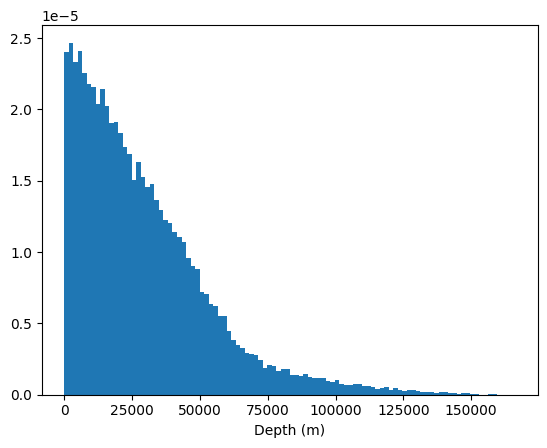

In [12]:
plt.hist(sample['Depth'], bins=100, density=True)
plt.xlabel('Depth (m)')

In [13]:
n_surf_samples = 5000
lon_surf = rng.uniform(lon_min, lon_max, n_surf_samples)
lat_surf = rng.uniform(lat_min, lat_max, n_surf_samples)

x_surf, y_surf = transformer.transform(lon_surf, lat_surf)
elev_surf = elev_interp(np.column_stack([lat_surf, lon_surf]))
z_surf = elev_surf

q0_surf = q0_interp(np.column_stack([lat_surf, lon_surf]))
k0_surf = k0_interp(np.column_stack([lat_surf, lon_surf]))
A0_surf = A0_interp(np.column_stack([lat_surf, lon_surf]))

mag_surf = mag_interp(np.column_stack([lat_surf, lon_surf]))
fa_surf = fa_interp(np.column_stack([lat_surf, lon_surf]))
boug_surf = boug_interp(np.column_stack([lat_surf, lon_surf]))
resistivity_surf = resistivity_interp(np.column_stack([lat_surf, lon_surf, np.zeros(n_surf_samples)]))
vp_surf = csrm_vp_interp(np.column_stack([lat_surf, lon_surf, np.zeros(n_surf_samples)]))
vs_surf = csrm_vs_interp(np.column_stack([lat_surf, lon_surf, np.zeros(n_surf_samples)]))

surf_sample = pd.DataFrame({
    "lon": lon_surf,
    "lat": lat_surf,
    "x": x_surf,
    "y": y_surf,
    "z": z_surf,
    "Depth": 0,
    "Region": 0,
    "HeatFlow0": q0_surf,
    "ThermalConductivity0": k0_surf,
    "HeatProduction0": A0_surf,
    "Temperature": 10 + 273.15,
    "HeatFlow": q0_surf,
    "ThermalConductivity": k0_surf,
    "Elevation": elev_surf,
    "MagneticAnomaly": mag_surf,
    "FreeairAnomaly": fa_surf,
    "BouguerAnomaly": boug_surf,
    'Resistivity': resistivity_surf,
    'Vp': vp_surf,
    'Vs': vs_surf,
    "x_n": (x_surf - xyz_m[0]) / xyz_l[0],
    "y_n": (y_surf - xyz_m[1]) / xyz_l[1],
    "z_n": (z_surf - xyz_m[2]) / xyz_l[2],
    "Elevation_n": (elev_surf - features_mean['Elevation']) / features_std['Elevation'],
    "MagneticAnomaly_n": (mag_surf - features_mean['MagneticAnomaly']) / features_std['MagneticAnomaly'],
    "FreeairAnomaly_n": (fa_surf - features_mean['FreeairAnomaly']) / features_std['FreeairAnomaly'],
    "BouguerAnomaly_n": (boug_surf - features_mean['BouguerAnomaly']) / features_std['BouguerAnomaly'],
    "Resistivity_n": (resistivity_surf - features_mean['Resistivity']) / features_std['Resistivity'],
    "Vp_n": (vp_surf - features_mean['Vp']) / features_std['Vp'],
    "Vs_n": (vs_surf - features_mean['Vs']) / features_std['Vs'],
})

surf_sample

,lon,lat,x,y,z,Depth,Region,HeatFlow0,ThermalConductivity0,HeatProduction0,...,x_n,y_n,z_n,Elevation_n,MagneticAnomaly_n,FreeairAnomaly_n,BouguerAnomaly_n,Resistivity_n,Vp_n,Vs_n
0,116.620766,38.464473,990538.518600,4.272345e+06,7.972320,0,0,61.619736,1.977879,1.470377,...,0.817877,0.737467,0.989660,-1.266536,0.283653,0.269045,1.364350,-0.159893,-3.822062,-5.113067
1,115.549307,36.688307,906548.742123,4.069951e+06,39.867855,0,0,69.467026,2.431112,1.543511,...,0.742042,0.444850,0.989852,-1.212340,-0.264157,-0.313437,1.105379,-0.148900,-3.598876,-4.448641
2,112.514591,39.618080,630005.278769,4.386465e+06,1347.693282,0,0,58.631420,2.156807,1.276499,...,0.492349,0.902459,0.997708,1.009876,-3.291489,1.238252,-0.538274,-0.153877,-3.019491,-3.443874
3,113.709678,37.163296,740604.363917,4.116426e+06,1571.664122,0,0,56.514591,2.070730,1.497307,...,0.592210,0.512042,0.999054,1.390441,-1.184879,3.367713,0.222718,-0.149881,-2.747623,-3.084259
4,115.304904,35.355844,891243.871047,3.921020e+06,54.907020,0,0,68.032755,2.686148,1.506558,...,0.728223,0.229529,0.989942,-1.186786,0.041037,-0.185908,1.071211,-0.216527,-4.062904,-5.082833
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,111.465109,34.783303,542553.727821,3.849111e+06,629.438407,0,0,66.180038,3.151605,1.530850,...,0.413388,0.125564,0.993394,-0.210560,0.229721,0.356478,0.439396,-0.186769,-2.899644,-3.384263
4996,113.842227,37.489094,751288.182554,4.152926e+06,1080.318136,0,0,55.801991,2.088481,1.479588,...,0.601856,0.564814,0.996102,0.555561,-0.011302,2.233507,0.271885,-0.156033,-2.794935,-3.146180
4997,106.945585,39.290543,150303.177424,4.356862e+06,1311.469752,0,0,60.196810,2.219177,1.063651,...,0.059223,0.859659,0.997491,0.948327,-0.593457,0.300749,-0.938931,-0.158239,-3.434030,-4.253057
4998,108.064977,37.661094,241102.499325,4.172267e+06,1389.011495,0,0,55.366161,2.272021,1.356764,...,0.141206,0.592777,0.997957,1.080083,-1.035174,-0.715978,-1.427351,-0.196169,-3.443325,-4.294635


In [14]:
lon_cp = rng.uniform(lon_min, lon_max, n_surf_samples)
lat_cp = rng.uniform(lat_min, lat_max, n_surf_samples)
x_cp, y_cp = transformer.transform(lon_cp, lat_cp)
z_cp = cp_interp(np.column_stack([lat_cp, lon_cp]))

elev_cp = elev_interp(np.column_stack([lat_cp, lon_cp]))
sed_cp = sed_interp(np.column_stack([lat_cp, lon_cp]))
uc_cp = uc_interp(np.column_stack([lat_cp, lon_cp]))
mc_cp = mc_interp(np.column_stack([lat_cp, lon_cp]))
lc_cp = lc_interp(np.column_stack([lat_cp, lon_cp]))

depth_cp = elev_cp - z_cp
depth_km_cp = depth_cp / 1e3

q0_cp = q0_interp(np.column_stack([lat_cp, lon_cp]))
k0_cp = k0_interp(np.column_stack([lat_cp, lon_cp]))
A0_cp = A0_interp(np.column_stack([lat_cp, lon_cp]))
q_cp = np.where(depth_cp<1.3e4, q0_cp-A0_cp*depth_cp/1e3, q0_cp-A0_cp*13-A0_cp*(1-np.exp(-(depth_cp-1.3e4)/1.3e4))*13)

region_cp = np.where(z_cp >= sed_cp, 0,
            np.where(z_cp >= uc_cp, 1,
            np.where(z_cp >= mc_cp, 2, 
            np.where(z_cp >= lc_cp, 3, 4))))

mag_cp = mag_interp(np.column_stack([lat_cp, lon_cp]))
fa_cp = fa_interp(np.column_stack([lat_cp, lon_cp]))
boug_cp = boug_interp(np.column_stack([lat_cp, lon_cp]))
resistivity_cp = resistivity_interp(np.column_stack([lat_cp, lon_cp, depth_km_cp]))
vp_cp = csrm_vp_interp(np.column_stack([lat_cp, lon_cp, depth_km_cp]))
vs_cp = csrm_vs_interp(np.column_stack([lat_cp, lon_cp, depth_km_cp]))

cp_sample = pd.DataFrame({
    "lon": lon_cp,
    "lat": lat_cp,
    "x": x_cp,
    "y": y_cp,
    "z": z_cp,
    "Depth": depth_cp,
    "Region": region_cp,
    "HeatFlow0": q0_cp,
    "ThermalConductivity0": k0_cp,
    "HeatProduction0": A0_cp,
    "Temperature": 580 + 273.15,
    "HeatFlow": q_cp,
    "Elevation": elev_cp,
    "MagneticAnomaly": mag_cp,
    "FreeairAnomaly": fa_cp,
    "BouguerAnomaly": boug_cp,
    'Resistivity': resistivity_cp,
    'Vp': vp_cp,
    'Vs': vs_cp,
    "x_n": (x_cp - xyz_m[0]) / xyz_l[0],
    "y_n": (y_cp - xyz_m[1]) / xyz_l[1],
    "z_n": (z_cp - xyz_m[2]) / xyz_l[2],
    "Elevation_n": (elev_cp - features_mean['Elevation']) / features_std['Elevation'],
    "MagneticAnomaly_n": (mag_cp - features_mean['MagneticAnomaly']) / features_std['MagneticAnomaly'],
    "FreeairAnomaly_n": (fa_cp - features_mean['FreeairAnomaly']) / features_std['FreeairAnomaly'],
    "BouguerAnomaly_n": (boug_cp - features_mean['BouguerAnomaly']) / features_std['BouguerAnomaly'],
    "Resistivity_n": (resistivity_cp - features_mean['Resistivity']) / features_std['Resistivity'],
    "Vp_n": (vp_cp - features_mean['Vp']) / features_std['Vp'],
    "Vs_n": (vs_cp - features_mean['Vs']) / features_std['Vs'],
})

cp_sample

,lon,lat,x,y,z,Depth,Region,HeatFlow0,ThermalConductivity0,HeatProduction0,...,x_n,y_n,z_n,Elevation_n,MagneticAnomaly_n,FreeairAnomaly_n,BouguerAnomaly_n,Resistivity_n,Vp_n,Vs_n
0,112.974695,36.874350,675999.157851,4.082754e+06,-30353.874618,31396.815403,2,61.520284,2.324039,1.533158,...,0.533877,0.463360,0.807266,0.492050,-1.280941,0.804037,-0.208700,-0.184814,-0.244438,-0.132247
1,114.772660,35.385540,842721.084524,3.922339e+06,-28023.476892,28082.042665,2,69.163652,2.923349,1.479657,...,0.684412,0.231435,0.821265,-1.180569,0.654811,-0.814047,0.883134,0.315688,-0.002484,0.067051
2,111.293658,39.564732,525224.979882,4.379490e+06,-29784.416429,31019.129605,2,65.207901,3.166768,1.140694,...,0.397742,0.892375,0.810687,0.817904,-0.771755,-0.154463,-0.740364,-0.229482,-0.296724,-0.015207
3,110.078060,36.682393,417628.491743,4.060036e+06,-33811.429162,34853.480371,2,69.563515,2.805356,1.450810,...,0.300593,0.430515,0.786495,0.490539,-0.450881,-0.710049,-0.740735,-0.228367,0.111544,0.215561
4,111.515318,35.551757,546706.004177,3.934356e+06,-34420.981102,35086.272391,2,69.019196,3.659364,1.516254,...,0.417138,0.248809,0.782833,-0.149640,1.791940,-0.341716,-0.015460,-0.251959,0.119042,0.173957
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,116.657850,39.857723,984094.566223,4.427312e+06,-27823.089078,27849.549122,2,66.608968,3.370604,1.265611,...,0.812059,0.961515,0.822469,-1.235122,-1.093857,0.167907,1.296926,-0.141017,-0.196654,-0.187456
4996,110.679587,37.346311,471620.659218,4.133339e+06,-33993.455832,34850.249883,2,67.714373,3.793348,1.350569,...,0.349342,0.536495,0.785402,0.175756,1.289566,-1.661482,-0.796880,-0.118456,0.117639,0.101859
4997,108.958380,35.450546,314712.763944,3.924924e+06,-30408.466612,31652.225121,2,71.909510,2.300380,1.583426,...,0.207669,0.235172,0.806938,0.833274,-0.665220,0.309227,-0.917621,-0.254363,0.008564,0.058910
4998,106.830782,38.742565,137605.617757,4.296469e+06,-24948.446919,26131.092965,1,59.183236,2.192982,1.153215,...,0.047758,0.772345,0.839738,0.729433,1.039868,-1.065196,-1.126818,-0.066634,-0.040005,-0.074899


In [15]:
lon_lab = rng.uniform(lon_min, lon_max, n_surf_samples)
lat_lab = rng.uniform(lat_min, lat_max, n_surf_samples)

x_lab, y_lab = transformer.transform(lon_lab, lat_lab)
z_lab = lab_interp(np.column_stack([lat_lab, lon_lab]))

elev_lab = elev_interp(np.column_stack([lat_lab, lon_lab]))
depth_lab = elev_lab - z_lab
depth_km_lab = depth_lab / 1e3

q0_lab = q0_interp(np.column_stack([lat_lab, lon_lab]))
k0_lab = k0_interp(np.column_stack([lat_lab, lon_lab]))
A0_lab = A0_interp(np.column_stack([lat_lab, lon_lab]))
q_lab = np.where(depth_lab<1.3e4, q0_lab-A0_lab*depth_lab/1e3, q0_lab-A0_lab*13-A0_lab*(1-np.exp(-(depth_lab-1.3e4)/1.3e4))*13)

mag_lab = mag_interp(np.column_stack([lat_lab, lon_lab]))
fa_lab = fa_interp(np.column_stack([lat_lab, lon_lab]))
boug_lab = boug_interp(np.column_stack([lat_lab, lon_lab]))
resistivity_lab = resistivity_interp(np.column_stack([lat_lab, lon_lab, depth_km_lab]))

vp_lab = np.empty_like(depth_km_lab, dtype=float)
vs_lab = np.empty_like(depth_km_lab, dtype=float)
mask = depth_km_lab <= 120
vp_lab[mask]  = csrm_vp_interp(np.column_stack([lat_lab[mask], lon_lab[mask], depth_km_lab[mask]]))
vp_lab[~mask] = lm_vp_interp(np.column_stack([lat_lab[~mask], lon_lab[~mask], depth_km_lab[~mask]]))
vs_lab[mask]  = csrm_vs_interp(np.column_stack([lat_lab[mask], lon_lab[mask], depth_km_lab[mask]]))
vs_lab[~mask] = lm_vs_interp(np.column_stack([lat_lab[~mask], lon_lab[~mask], depth_km_lab[~mask]]))


lab_sample = pd.DataFrame({
    "lon": lon_lab,
    "lat": lat_lab,
    "x": x_lab,
    "y": y_lab,
    "z": z_lab,
    "Depth": depth_lab,
    "Region": 4,
    "HeatFlow0": q0_lab,
    "ThermalConductivity0": k0_lab,
    "HeatProduction0": A0_lab,
    "Temperature": 1300 + 273.15,
    "HeatFlow": q_lab,
    "Elevation": elev_lab,
    "MagneticAnomaly": mag_lab,
    "FreeairAnomaly": fa_lab,
    "BouguerAnomaly": boug_lab,
    'Resistivity': resistivity_lab,
    'Vp': vp_lab,
    'Vs': vs_lab,
    "x_n": (x_lab - xyz_m[0]) / xyz_l[0],
    "y_n": (y_lab - xyz_m[1]) / xyz_l[1],
    "z_n": (z_lab - xyz_m[2]) / xyz_l[2],
    "Elevation_n": (elev_lab - features_mean['Elevation']) / features_std['Elevation'],
    "MagneticAnomaly_n": (mag_lab - features_mean['MagneticAnomaly']) / features_std['MagneticAnomaly'],
    "FreeairAnomaly_n": (fa_lab - features_mean['FreeairAnomaly']) / features_std['FreeairAnomaly'],
    "BouguerAnomaly_n": (boug_lab - features_mean['BouguerAnomaly']) / features_std['BouguerAnomaly'],
    "Resistivity_n": (resistivity_lab - features_mean['Resistivity']) / features_std['Resistivity'],
    "Vp_n": (vp_lab - features_mean['Vp']) / features_std['Vp'],
    "Vs_n": (vs_lab - features_mean['Vs']) / features_std['Vs'],
})

lab_sample

,lon,lat,x,y,z,Depth,Region,HeatFlow0,ThermalConductivity0,HeatProduction0,...,x_n,y_n,z_n,Elevation_n,MagneticAnomaly_n,FreeairAnomaly_n,BouguerAnomaly_n,Resistivity_n,Vp_n,Vs_n
0,108.322797,34.679148,2.547193e+05,3.840725e+06,-97006.239055,97851.378042,4,70.366496,2.428991,1.626617,...,0.153501,0.113439,0.406862,0.155952,-0.974777,-1.574821,-0.849227,-0.207573,1.316098,1.314848
1,118.098440,38.759397,1.117085e+06,4.314077e+06,-68470.513929,68457.404138,4,65.931401,2.085231,1.294679,...,0.932137,0.797802,0.578286,-1.302358,-0.785104,0.264364,1.412156,-0.156496,1.580156,1.012705
2,108.978923,34.201875,3.137863e+05,3.786386e+06,-89628.065807,90142.001169,4,72.041342,2.145994,1.612401,...,0.206833,0.034878,0.451185,-0.406819,-0.649802,-2.681991,-0.820688,0.022062,1.437250,1.192216
3,114.473639,39.148184,8.001977e+05,4.338970e+06,-66825.478170,67731.576275,4,62.087006,1.862397,1.344505,...,0.646017,0.833792,0.588168,0.259532,-0.575052,0.861270,0.130071,-0.147510,1.163096,0.942755
4,118.427775,39.060987,1.143003e+06,4.349890e+06,-64149.545587,64147.868320,4,70.060516,2.516511,1.218340,...,0.955538,0.849581,0.604244,-1.282932,0.262516,0.325989,1.434154,-0.154528,1.372028,0.899543
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,111.122780,38.655897,5.106830e+05,4.278599e+06,-74881.755528,76086.000219,4,65.065781,3.180346,1.185032,...,0.384612,0.746509,0.539772,0.766133,-2.076067,-0.348878,-0.824010,-0.258250,1.213164,1.256234
4996,113.547035,37.459621,7.252733e+05,4.148908e+06,-74579.172572,75935.273207,4,57.194421,2.122813,1.481006,...,0.578367,0.559004,0.541589,1.024162,-0.497159,2.861644,0.116507,-0.107029,1.199163,0.997760
4997,114.987278,36.300869,8.580810e+05,4.024703e+06,-64295.595276,64345.615242,4,68.450807,2.617659,1.511734,...,0.698280,0.379432,0.603366,-1.195090,-1.110219,-0.686639,0.936334,0.123804,1.267449,1.098893
4998,115.699755,38.608963,9.092929e+05,4.283872e+06,-61905.477684,61918.921159,4,65.281364,1.767298,1.422922,...,0.744520,0.754133,0.617725,-1.257240,-0.403778,-0.703007,1.003372,-0.090470,1.291858,0.974831


In [16]:
lon_moho = rng.uniform(lon_min, lon_max, n_surf_samples)
lat_moho = rng.uniform(lat_min, lat_max, n_surf_samples)

x_moho, y_moho = transformer.transform(lon_moho, lat_moho)
z_moho = moho_interp(np.column_stack([lat_moho, lon_moho]))

elev_moho = elev_interp(np.column_stack([lat_moho, lon_moho]))
depth_moho = elev_moho - z_moho
depth_km_moho = depth_moho / 1e3

q0_moho = q0_interp(np.column_stack([lat_moho, lon_moho]))
k0_moho = k0_interp(np.column_stack([lat_moho, lon_moho]))
A0_moho = A0_interp(np.column_stack([lat_moho, lon_moho]))
q_moho = np.where(depth_moho<1.3e4, q0_moho-A0_moho*depth_moho/1e3, q0_moho-A0_moho*13-A0_moho*(1-np.exp(-(depth_moho-1.3e4)/1.3e4))*13)

mag_moho = mag_interp(np.column_stack([lat_moho, lon_moho]))
fa_moho = fa_interp(np.column_stack([lat_moho, lon_moho]))
boug_moho = boug_interp(np.column_stack([lat_moho, lon_moho]))
resistivity_moho = resistivity_interp(np.column_stack([lat_moho, lon_moho, depth_km_moho]))
vp_moho = csrm_vp_interp(np.column_stack([lat_moho, lon_moho, depth_km_moho]))
vs_moho = csrm_vs_interp(np.column_stack([lat_moho, lon_moho, depth_km_moho]))

moho_sample = pd.DataFrame({
    "lon": lon_moho,
    "lat": lat_moho,
    "x": x_moho,
    "y": y_moho,
    "z": z_moho,
    "Depth": depth_moho,
    "Region": 3,
    "HeatFlow0": q0_moho,
    "ThermalConductivity0": k0_moho,
    "HeatProduction0": A0_moho,
    "HeatFlow": q_moho,
    "Elevation": elev_moho,
    "MagneticAnomaly": mag_moho,
    "FreeairAnomaly": fa_moho,
    "BouguerAnomaly": boug_moho,
    'Resistivity': resistivity_moho,
    'Vp': vp_moho,
    'Vs': vs_moho,
    "x_n": (x_moho - xyz_m[0]) / xyz_l[0],
    "y_n": (y_moho - xyz_m[1]) / xyz_l[1],
    "z_n": (z_moho - xyz_m[2]) / xyz_l[2],
    "Elevation_n": (elev_moho - features_mean['Elevation']) / features_std['Elevation'],
    "MagneticAnomaly_n": (mag_moho - features_mean['MagneticAnomaly']) / features_std['MagneticAnomaly'],
    "FreeairAnomaly_n": (fa_moho - features_mean['FreeairAnomaly']) / features_std['FreeairAnomaly'],
    "BouguerAnomaly_n": (boug_moho - features_mean['BouguerAnomaly']) / features_std['BouguerAnomaly'],
    "Resistivity_n": (resistivity_moho - features_mean['Resistivity']) / features_std['Resistivity'],
    "Vp_n": (vp_moho - features_mean['Vp']) / features_std['Vp'],
    "Vs_n": (vs_moho - features_mean['Vs']) / features_std['Vs'],
})

moho_sample

,lon,lat,x,y,z,Depth,Region,HeatFlow0,ThermalConductivity0,HeatProduction0,...,x_n,y_n,z_n,Elevation_n,MagneticAnomaly_n,FreeairAnomaly_n,BouguerAnomaly_n,Resistivity_n,Vp_n,Vs_n
0,109.229166,35.943983,3.402781e+05,3.979184e+06,-44148.040205,45319.376263,3,71.730441,2.269421,1.576773,...,0.230752,0.313621,0.724400,0.710216,0.267000,-0.068757,-0.627797,-0.057151,0.634708,0.860535
1,116.964282,34.963106,1.044834e+06,3.885237e+06,-36306.512753,36346.357849,3,58.654048,2.530734,1.451283,...,0.866901,0.177793,0.771506,-1.212379,0.149663,0.283533,1.370980,0.346556,0.846552,1.010946
2,115.572852,38.637992,8.980749e+05,4.286536e+06,-33636.709418,33653.196902,3,65.281364,1.822280,1.407538,...,0.734391,0.757984,0.787545,-1.252067,-0.413857,-0.820028,0.942010,-0.122126,0.883382,0.686337
3,118.476709,35.785859,1.176284e+06,3.986086e+06,-35794.511814,35999.811902,3,72.812600,2.956514,1.446162,...,0.985588,0.323599,0.774582,-0.931243,-0.143940,0.504127,1.219256,-0.146729,0.668204,0.745755
4,116.171835,36.038836,9.660926e+05,4.000652e+06,-34236.166678,34276.747370,3,75.358475,2.813804,1.505167,...,0.795805,0.344658,0.783944,-1.211129,0.881902,0.232990,1.305929,-0.274242,0.477708,0.608380
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,113.507168,37.941928,7.203135e+05,4.202337e+06,-39387.677062,40343.046927,3,57.628553,2.125688,1.418591,...,0.573889,0.636250,0.752997,0.343253,1.457338,0.931466,-0.022474,-0.142915,0.680192,0.627567
4996,115.696224,35.529776,9.259137e+05,3.941953e+06,-33857.288558,33906.331977,3,69.683365,2.599503,1.537957,...,0.759527,0.259792,0.786220,-1.196749,0.627030,0.267611,1.335569,-0.253508,0.651504,0.623182
4997,110.317357,38.511394,4.404840e+05,4.262779e+06,-41541.410504,42614.236227,3,66.927634,3.149494,1.115846,...,0.321229,0.723636,0.740059,0.542830,-1.204421,-0.449924,-0.794190,-0.266242,0.749781,0.650884
4998,116.721321,38.715843,9.975757e+05,4.300811e+06,-34522.607748,34528.753809,3,61.218929,1.920362,1.460134,...,0.824231,0.778623,0.782223,-1.269639,-0.069328,0.309154,1.361095,-0.124132,0.666790,0.548655


In [18]:
coord_cols = ["x_n", "y_n", "z_n"]
feature_cols = ["Elevation_n", "MagneticAnomaly_n", "FreeairAnomaly_n", "BouguerAnomaly_n", "Resistivity_n", "Vp_n", "Vs_n"]


In [25]:
# 1) 取所有样本的 3D 归一化坐标
coords = sample[coord_cols].values   # (N,3)

# 2) 建 KNN（k 个邻居，+1 是因为第一个是自己）
k = 64
nns = NearestNeighbors(n_neighbors=k+1, algorithm='kd_tree')
nns.fit(coords)

dist, idx = nns.kneighbors(coords)
neighbor_idx = idx[:, 1:]             # (N, k)

neighbor_idx_t = torch.tensor(neighbor_idx, dtype=torch.long, device=device)

In [13]:
class PINN(nn.Module):
    def __init__(self, in_dim=3, out_dim=1, hidden_dim=[64, 64, 64], T0=800.0, dT=1000.0):
        super().__init__()
        self.T0 = T0
        self.dT = dT

        layers = []
        prev = in_dim

        for h in hidden_dim:
            layers.append(nn.Linear(prev, h))
            layers.append(nn.Tanh())
            prev = h

        layers.append(nn.Linear(prev, out_dim))
        self.f = nn.Sequential(*layers)

    def forward(self, xyz, features):
        x = torch.cat([xyz, features], dim=-1)
        theta = self.f(x)
        return self.T0 + self.dT * theta  # [N,1]


In [14]:
def k_func(T, dh, k0, region):
    """ region: 0=sediment, 1=upper crust, 2=middle crust, 3=lower crust, 4=mantle """
    b = torch.tensor([1e-3, 1e-3, 5e-4, 1.5e-4, 0.0], device=T.device)[region].unsqueeze(1)
    c = 1.5e-3/1e3  # km^-1→m^-1
    k_crust = k0*(1+c*dh)/(1+b*(T-293.15))
    k_mantle = k0*(1.23e-10*T**3 + 1/(0.518+7.89e-4*T))
    mask = (region < 4).view(-1, 1)
    return torch.where(mask, k_crust, k_mantle)

def A_func(A0, dh, D0=1.3e4, D1=1.3e4):
    return torch.where(dh < D0, A0, A0*torch.exp(-(dh-D0)/D1))


In [15]:
def pde_residual(model, sample, debug=False):
    xyz_n = torch.tensor(sample[coord_cols].values, dtype=torch.float32, device=device, requires_grad=True)
    features_n = torch.tensor(sample[feature_cols].values, dtype=torch.float32, device=device)
    k0 = torch.tensor(sample['ThermalConductivity0'].values, device=device)[:, None]
    A0 = torch.tensor(sample['HeatProduction0'].values, device=device)[:, None]
    depth = torch.tensor(sample['Depth'].values, device=device)[:, None]
    region = torch.tensor(sample['Region'].values, dtype=torch.long, device=device)
    T = model(xyz_n, features_n)
    gradT_n = torch.autograd.grad(T, xyz_n, torch.ones_like(T), create_graph=True)[0]
    k = k_func(T, depth, k0, region)
    A = A_func(A0, depth)
    div = torch.zeros_like(T)
    for i in range(3):
        out = k * (gradT_n[:, i:i+1] / xyz_l[i])
        d = torch.autograd.grad(out, xyz_n, torch.ones_like(out), create_graph=True)[0][:, i:i+1]
        div += d / xyz_l[i]
    div *= 1e6 # W/m^3 → μW/m^3，与 A 单位一致
    residual = (div + A)**2

    if debug:
        dTdx = gradT_n[:, 0:1] / xyz_l[0]
        dTdy = gradT_n[:, 1:2] / xyz_l[1]
        dTdz = gradT_n[:, 2:3] / xyz_l[2]
        print("\n==== PDE loss debug ====")
        print(f"T range: [{T.min().item():.2e}, {T.max().item():.2e}] K")
        print(f"dTdx range: [{dTdx.min().item()*1e3:.2e}, {dTdx.max().item()*1e3:.2e}] K/km")
        print(f"dTdy range: [{dTdy.min().item()*1e3:.2e}, {dTdy.max().item()*1e3:.2e}] K/km")
        print(f"dTdz range: [{dTdz.min().item()*1e3:.2e}, {dTdz.max().item()*1e3:.2e}] K/km")
        print(f"k range: [{k.min().item():.2e}, {k.max().item():.2e}] W/m/K")
        print(f"A range: [{A.min().item():.2e}, {A.max().item():.2e}] μW/m^3")
        print(f"div range: [{div.min().item():.2e}, {div.max().item():.2e}] μW/m^3")
        print(f"residual range: [{residual.min().item():.2e}, {residual.max().item():.2e}] (μW/m^3)^2")
        print(f"residual mean: {residual.mean().item():.2e} (μW/m^3)^2")
    
    return residual.mean()


In [16]:
def T_loss(model, df):
    xyz_n = torch.tensor(df[coord_cols].values, dtype=torch.float32, device=device)
    features_n = torch.tensor(df[feature_cols].values, dtype=torch.float32, device=device)
    T = torch.tensor(df['Temperature'].values, dtype=torch.float32, device=device)[:, None]
    T_pred = model(xyz_n, features_n)
    return ((T_pred - T)**2).mean()

def q_loss(model, df, debug=False):
    xyz_n = torch.tensor(df[coord_cols].values, dtype=torch.float32, device=device, requires_grad=True)
    features_n = torch.tensor(df[feature_cols].values, dtype=torch.float32, device=device)
    k0 = torch.tensor(df['ThermalConductivity0'].values, device=device)[:, None]
    q = torch.tensor(df['HeatFlow'].values, device=device)[:, None]
    depth = torch.tensor(df['Depth'].values, device=device)[:, None]
    region = torch.tensor(df['Region'].values, dtype=torch.long, device=device)
    T = model(xyz_n, features_n)
    dTdz = torch.autograd.grad(T, xyz_n, torch.ones_like(T), create_graph=True)[0][:, 2:3] / xyz_l[2]
    k = k_func(T, depth, k0, region)
    q_pred = -k*dTdz*1e3
    residual = (q_pred - q)**2

    if debug:
        print("==== q loss debug ====")
        print(f"T range: [{T.min().item():.2e}, {T.max().item():.2e}] K")
        print(f"dTdz range: [{dTdz.min().item()*1e3:.2e}, {dTdz.max().item()*1e3:.2e}] K/km")
        print(f"q_pred range: [{q_pred.min().item():.2e}, {q_pred.max().item():.2e}] mW/m^2")
        print(f"residual range: [{residual.min().item():.2e}, {residual.max().item():.2e}] (mW/m^2)^2")
        print(f"residual mean: {residual.mean().item():.2e} (mW/m^2)^2")
    
    return residual.mean()


In [17]:
def knn_grad_smooth_loss(model, df, neighbor_idx_t):
    """
    用 K 近邻在 3D 空间上平滑 ∇T：
    对每个样本 i 和其邻居 j，惩罚 (gradT_i - gradT_j)^2。
    """

    # 1) 全量坐标 & 物理量
    xyz_n = torch.tensor(df[coord_cols].values, dtype=torch.float32, device=device, requires_grad=True)
    features_n = torch.tensor(df[feature_cols].values, dtype=torch.float32, device=device)

    # 2) 网络输出 & 一阶梯度
    T = model(xyz_n, features_n)   # (N,1)

    gradT_n = torch.autograd.grad(T, xyz_n, torch.ones_like(T), create_graph=True)[0] # (N,3)，对归一化坐标的梯度
    scale = torch.tensor(xyz_l, dtype=torch.float32, device=device).view(1, 3)
    gradT = gradT_n / scale

    N, k = neighbor_idx_t.shape

    # 3) 构造 i、j 的梯度张量
    # 每个 i 的索引 [i, i, ..., i] (k 次)
    idx_i = torch.arange(N, device=device).unsqueeze(1).expand(-1, k)  # (N,k)
    grad_i = gradT[idx_i]             # (N,k,3)
    grad_j = gradT[neighbor_idx_t]    # (N,k,3)

    diff = grad_i - grad_j            # (N,k,3)
    diff2 = (diff ** 2).sum(dim=2)    # (N,k)，每条边的 |Δ∇T|^2

    # 对每个点，把它与 k 个邻居的 diff2 求平均，然后乘权重再整体平均
    loss = diff2.mean(dim=1, keepdim=True).mean()
    return loss

In [53]:
model = PINN(in_dim=len(coord_cols)+len(feature_cols)).to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

for it in range(1, 1001):

    opt.zero_grad()
    stats = {}

    lpde    = pde_residual(model, sample) * 1e3
    lq      = q_loss(model, sample)
    lsurfT  = T_loss(model, surf_sample)
    lsurfq  = q_loss(model, surf_sample)
    lcpT    = T_loss(model, cp_sample)
    lcpq    = q_loss(model, cp_sample)
    llabT   = T_loss(model, lab_sample)
    llabq   = q_loss(model, lab_sample)
    lsmooth = knn_grad_smooth_loss(model, sample, neighbor_idx_t) * 1e3

    loss = (
        lpde
        + lsurfT + lsurfq
        + lcpT + lcpq
        + llabT
        + lsmooth
    )

    stats["loss"]    = loss
    stats["lpde"]    = lpde
    stats["lq"]      = lq
    stats["lsurfT"]  = lsurfT
    stats["lsurfq"]  = lsurfq
    stats["lcpT"]    = lcpT
    stats["lcpq"]    = lcpq
    stats["llabT"]   = llabT
    stats["llabq"]   = llabq
    stats["lsmooth"] = lsmooth

    loss.backward()
    opt.step()

    if it % 100 == 0:
        print(
            f"{it}: total={stats['loss'].item():.3e}, "
            f"pde={stats['lpde'].item():.3e}, "
            f"q={stats['lq'].item():.3e}, "
            f"surfT={stats['lsurfT'].item():.3e}, "
            f"surfq={stats['lsurfq'].item():.3e}, "
            f"cpT={stats['lcpT'].item():.3e}, "
            f"cpq={stats['lcpq'].item():.3e}, "
            f"labT={stats['llabT'].item():.3e}, "
            f"labq={stats['llabq'].item():.3e}, "
            f"smooth={stats['lsmooth'].item():.3e}"
        )


100: total=1.949e+04, pde=8.439e+02, q=1.526e+03, surfT=1.607e+02, surfq=4.026e+03, cpT=9.633e+03, cpq=8.950e+02, labT=3.928e+03, labq=6.345e+02, smooth=4.767e-05
200: total=1.608e+04, pde=8.447e+02, q=1.508e+03, surfT=1.854e+02, surfq=4.037e+03, cpT=7.421e+03, cpq=8.740e+02, labT=2.716e+03, labq=6.085e+02, smooth=5.824e-05
300: total=1.426e+04, pde=8.451e+02, q=1.467e+03, surfT=3.552e+02, surfq=4.000e+03, cpT=5.961e+03, cpq=8.353e+02, labT=2.263e+03, labq=5.682e+02, smooth=7.405e-05
400: total=1.300e+04, pde=8.449e+02, q=1.413e+03, surfT=3.644e+02, surfq=3.921e+03, cpT=4.986e+03, cpq=7.861e+02, labT=2.095e+03, labq=5.250e+02, smooth=9.310e-05
500: total=1.171e+04, pde=8.441e+02, q=1.353e+03, surfT=2.811e+02, surfq=3.817e+03, cpT=4.051e+03, cpq=7.309e+02, labT=1.986e+03, labq=4.816e+02, smooth=1.179e-04
600: total=1.046e+04, pde=8.423e+02, q=1.289e+03, surfT=2.365e+02, surfq=3.699e+03, cpT=3.238e+03, cpq=6.741e+02, labT=1.769e+03, labq=4.448e+02, smooth=1.538e-04
700: total=9.029e+03, 

In [54]:
model.train()

opt = torch.optim.LBFGS(
    model.parameters(),
    lr=1.0,
    max_iter=20,
    history_size=100,
    line_search_fn="strong_wolfe",
)

for it in range(1001, 1201):
    stats = {}

    def closure():
        opt.zero_grad()

        # PDE loss
        lpde    = pde_residual(model, sample) * 1e3
        lq      = q_loss(model, sample)
        lsurfT  = T_loss(model, surf_sample)
        lsurfq  = q_loss(model, surf_sample)
        lcpT    = T_loss(model, cp_sample)
        lcpq    = q_loss(model, cp_sample)
        llabT   = T_loss(model, lab_sample)
        llabq   = q_loss(model, lab_sample)
        lsmooth = knn_grad_smooth_loss(model, sample, neighbor_idx_t) * 1e3

        loss = (
            lpde
            + lsurfT + lsurfq
            + lcpT + lcpq
            + llabT + llabq
            + lsmooth
        )

        loss.backward()

        stats["loss"]    = loss
        stats["lpde"]    = lpde
        stats["lq"]      = lq
        stats["lsurfT"]  = lsurfT
        stats["lsurfq"]  = lsurfq
        stats["lcpT"]    = lcpT
        stats["lcpq"]    = lcpq
        stats["llabT"]   = llabT
        stats["llabq"]   = llabq
        stats["lsmooth"] = lsmooth

        return loss

    opt.step(closure)
    print(
        f"{it}: total={stats['loss'].item():.3e}, "
        f"pde={stats['lpde'].item():.3e}, "
        f"q={stats['lq'].item():.3e}, "
        f"surfT={stats['lsurfT'].item():.3e}, "
        f"surfq={stats['lsurfq'].item():.3e}, "
        f"cpT={stats['lcpT'].item():.3e}, "
        f"cpq={stats['lcpq'].item():.3e}, "
        f"labT={stats['llabT'].item():.3e}, "
        f"labq={stats['llabq'].item():.3e}, "
        f"smooth={stats['lsmooth'].item():.3e}"
    )


1001: total=4.566e+03, pde=7.076e+02, q=7.265e+02, surfT=1.579e+02, surfq=1.991e+03, cpT=4.472e+02, cpq=2.729e+02, labT=6.404e+02, labq=3.495e+02, smooth=1.076e-03
1002: total=3.916e+03, pde=6.097e+02, q=5.628e+02, surfT=2.722e+02, surfq=1.405e+03, cpT=3.892e+02, cpq=1.888e+02, labT=7.071e+02, labq=3.443e+02, smooth=1.151e-03
1003: total=3.138e+03, pde=4.787e+02, q=4.091e+02, surfT=1.283e+02, surfq=8.841e+02, cpT=4.425e+02, cpq=1.227e+02, labT=7.182e+02, labq=3.635e+02, smooth=1.448e-03
1004: total=2.527e+03, pde=2.882e+02, q=2.515e+02, surfT=1.906e+02, surfq=3.813e+02, cpT=5.069e+02, cpq=7.847e+01, labT=7.087e+02, labq=3.730e+02, smooth=1.948e-03
1005: total=1.953e+03, pde=1.870e+02, q=1.961e+02, surfT=1.203e+02, surfq=2.035e+02, cpT=5.613e+02, cpq=7.669e+01, labT=4.383e+02, labq=3.663e+02, smooth=2.162e-03
1006: total=1.613e+03, pde=1.681e+02, q=2.062e+02, surfT=7.288e+01, surfq=1.502e+02, cpT=4.707e+02, cpq=8.321e+01, labT=2.621e+02, labq=4.058e+02, smooth=2.548e-03
1007: total=1.48

In [72]:
# 保存模型
torch.save(model.state_dict(), "model-test05.pth")

In [19]:
model = PINN(in_dim=len(coord_cols)+len(feature_cols)).to(device)
model.load_state_dict(torch.load("model-test05.pth", map_location=torch.device('cpu')))

<All keys matched successfully>

In [20]:
model.eval()

PINN(
  (f): Sequential(
    (0): Linear(in_features=10, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [21]:
def predict_fields(lon, lat, z):
    """
    输入:
        lon, lat, z: 1D 或广播后能拉直的一维数组，长度相同
            lon, lat 单位: 度
            z 单位: m (和 sample['z'] 一样，向下为负数)
    输出:
        字典 { 'T', 'q', 'k', 'A', 'pde', 'depth_km', 'lon', 'lat', 'z' }
        其中 q 单位 mW/m^2, A 单位 μW/m^3,
        pde 单位 (μW/m^3)^2（对应 pde_residual 中的 (div + A)^2）
    """
    lon = np.asarray(lon).ravel()
    lat = np.asarray(lat).ravel()
    z   = np.asarray(z).ravel()
    assert lon.shape == lat.shape == z.shape

    # 插值地表及分层信息
    pts   = np.column_stack([lat, lon])  # 注意前面你用的是 [lat, lon]
    k0    = k0_interp(pts)               # W/m/K
    A0    = A0_interp(pts)               # μW/m^3 (和 pde 中一致)
    elev  = elev_interp(pts)             # m
    sed   = sed_interp(pts)
    uc    = uc_interp(pts)
    mc    = mc_interp(pts)
    lc    = lc_interp(pts)
    cp    = cp_interp(pts)
    lab   = lab_interp(pts)
    depth = elev - z
    depth_km = depth / 1e3

    # 分层编码 (和 sample 中保持一致)
    region = np.where(z >= sed, 0,
              np.where(z >= uc, 1,
              np.where(z >= mc, 2,
              np.where(z >= lc, 3, 4))))

    # 坐标投影 + 归一化
    x, y = transformer.transform(lon, lat)  # EPSG:32649
    x_n = (x - xyz_m[0]) / xyz_l[0]
    y_n = (y - xyz_m[1]) / xyz_l[1]
    z_n = (z - xyz_m[2]) / xyz_l[2]

    # 插值其他观测zhi
    mag  = mag_interp(pts)
    fa   = fa_interp(pts)
    boug = boug_interp(pts)
    resistivity = resistivity_interp(np.column_stack([lat, lon, depth_km]))
    vp = np.empty_like(depth_km, dtype=float)
    vs = np.empty_like(depth_km, dtype=float)
    mask = depth_km <= 120
    vp[mask]  = csrm_vp_interp(np.column_stack([lat[mask], lon[mask], depth_km[mask]]))
    vp[~mask] = lm_vp_interp(np.column_stack([lat[~mask], lon[~mask], depth_km[~mask]]))
    vs[mask]  = csrm_vs_interp(np.column_stack([lat[mask], lon[mask], depth_km[mask]]))
    vs[~mask] = lm_vs_interp(np.column_stack([lat[~mask], lon[~mask], depth_km[~mask]]))

    # 归一化特征
    elev_n = (elev - features_mean['Elevation']) / features_std['Elevation']
    mag_n  = (mag - features_mean['MagneticAnomaly']) / features_std['MagneticAnomaly']
    fa_n   = (fa - features_mean['FreeairAnomaly']) / features_std['FreeairAnomaly']
    boug_n = (boug - features_mean['BouguerAnomaly']) / features_std['BouguerAnomaly']
    resistivity_n = (resistivity - features_mean['Resistivity']) / features_std['Resistivity']
    vp_n   = (vp - features_mean['Vp']) / features_std['Vp']
    vs_n   = (vs - features_mean['Vs']) / features_std['Vs']

    xyz_n = torch.tensor(
        np.column_stack([x_n, y_n, z_n]),
        dtype=torch.float32, device=device, requires_grad=True
    )
    features_n = torch.tensor(
        np.column_stack([elev_n, mag_n, fa_n, boug_n, resistivity_n, vp_n, vs_n]),
        dtype=torch.float32, device=device
    )

    # 物性张量
    k0_t   = torch.tensor(k0,  dtype=torch.float32, device=device)[:, None]
    A0_t   = torch.tensor(A0,  dtype=torch.float32, device=device)[:, None]
    region_t = torch.tensor(region, dtype=torch.long, device=device)
    elev_t = torch.tensor(elev, dtype=torch.float32, device=device)[:, None]
    z_t    = torch.tensor(z,    dtype=torch.float32, device=device)[:, None]

    # 前向：温度
    T = model(xyz_n, features_n)  # K

    # 梯度 -> dT/dz (K/m)
    gradT_n = torch.autograd.grad(T, xyz_n, torch.ones_like(T), create_graph=True)[0]
    dTdz = gradT_n[:, 2:3] / xyz_l[2]

    # k(T, depth), A(depth)
    k  = k_func(T, elev_t - z_t, k0_t, region_t) # W/m/K
    A  = A_func(A0_t, elev_t - z_t)              # μW/m^3

    # 热流 (mW/m^2) = -k dT/dz * 1e3
    q = -k * dTdz * 1e3

    # PDE 残差 (与 pde_residual 中一致): (div + A)^2, 单位约 (μW/m^3)^2
    div = 0
    for i in range(3):
        # gradT_n 是对归一化坐标 xyz_n 的梯度，这里要除以对应的尺度 xyz_l[i]
        out = k * (gradT_n[:, i:i+1] / xyz_l[i])
        d = torch.autograd.grad(out, xyz_n, torch.ones_like(out), create_graph=True)[0][:, i:i+1]
        div += d / xyz_l[i]
    div = div * 1e6  # 转为 μW/m^3

    pde_res = (div + A) ** 2  # (μW/m^3)^2

    out = {
        "lon": lon,
        "lat": lat,
        "z": z,
        "depth_km": depth_km,
        "T": T.detach().cpu().numpy().reshape(lon.shape),
        "q": q.detach().cpu().numpy().reshape(lon.shape),
        "k": k.detach().cpu().numpy().reshape(lon.shape),
        "A": A.detach().cpu().numpy().reshape(lon.shape),
        "pde": pde_res.detach().cpu().numpy().reshape(lon.shape),
        "elev": elev,
        "sed": sed,
        "uc": uc,
        "mc": mc,
        "lc": lc,
        "cp": cp,
        "lab": lab,
        "region": region,
    }
    return out


In [22]:
lon_min, lon_max, dlon = 106.5, 118.5, 0.25
lat_min, lat_max, dlat = 34.0, 40.0, 0.25
ddepth_km = 2.0

lons = np.arange(lon_min, lon_max + 1e-12, dlon)
lats = np.arange(lat_min, lat_max + 1e-12, dlat)

lon_all, lat_all, depth_all = [], [], []

for lat0 in lats:
    for lon0 in lons:
        pts = np.array([[lat0, lon0]])
        elev0 = float(elev_interp(pts)[0])
        lab0 = float(lab_interp(pts)[0])
        lab_depth_km = (elev0 - lab0) / 1e3

        if not np.isfinite(lab_depth_km) or lab_depth_km <= 0:
            continue

        d = np.arange(0.0, lab_depth_km, ddepth_km)
        if (len(d) == 0) or (abs(d[-1] - lab_depth_km) > 1e-9):
            d = np.append(d, lab_depth_km)

        n = len(d)
        lon_all.append(np.full(n, lon0))
        lat_all.append(np.full(n, lat0))
        depth_all.append(d)

lon = np.concatenate(lon_all)
lat = np.concatenate(lat_all)
depth_km = np.concatenate(depth_all)

pts = np.column_stack([lat, lon])
elev = elev_interp(pts)
z = elev - depth_km * 1e3

# 换成你现在的新函数名，比如 predict_fields_v2
pred = predict_fields(lon, lat, z)

out = pd.DataFrame({
    "Lon": lon,
    "Lat": lat,
    "Depth_km": depth_km,
    "Temperature_K": pred["T"],
    "Thermal_Conductivity_W_mK": pred["k"],
    "Heat_Production_W_m3": pred["A"] * 1e-6,
    "Heat_Flux_mW_m2": pred["q"],
})

out.to_csv("result-test05.csv", index=False)
print("rows:", len(out))
print("result-test05.csv")

rows: 55515
result-test05.csv


In [29]:
def plot_vertical_profile(lon0, lat0, nz=200):
    """
    在指定经纬度 (lon0, lat0) 处，绘制 T/q/k/A 随深度变化的 1D 剖面，
    并在图上标出 cp、sed、uc、mc、lc 的深度（横虚线）。
    """
    # ---- 1) 该点的地表 / 界面深度 ----
    pts = np.array([[lat0, lon0]])  # 注意顺序 [lat, lon]
    elev0 = elev_interp(pts)[0]    # 地表 z (m)
    lab0  = lab_interp(pts)[0]     # LAB z (m)
    z_col = np.linspace(elev0, lab0, nz)  # z (m)

    # ---- 2) 调用通用预测函数 ----
    out = predict_fields(lon=np.full(nz, lon0), lat=np.full(nz, lat0), z=z_col)
    depth_km = out["depth_km"]
    T_prof   = out["T"]
    q_prof   = out["q"]
    k_prof   = out["k"]
    A_prof   = out["A"]
    pde_prof = out["pde"]

    elev0 = out["elev"]
    sed_depth_km = ((elev0 - out["sed"]) / 1e3)[0]
    uc_depth_km  = ((elev0 - out["uc"]) / 1e3)[0]
    mc_depth_km  = ((elev0 - out["mc"]) / 1e3)[0]
    lc_depth_km  = ((elev0 - out["lc"]) / 1e3)[0]
    cp_depth_km  = ((elev0 - out["cp"]) / 1e3)[0]
    lab_depth_km = ((elev0 - out["lab"]) / 1e3)[0]

    idx = np.argsort(depth_km)
    depth_km = depth_km[idx]
    T_prof   = T_prof[idx]
    q_prof   = q_prof[idx]
    k_prof   = k_prof[idx]
    A_prof   = A_prof[idx]
    pde_prof = pde_prof[idx]

    # ---- 3) 画图 ----
    fig, axes = plt.subplots(1, 5, figsize=(16, 5), sharey=True)

    # 温度
    axes[0].plot(T_prof, depth_km)
    axes[0].set_xlabel("T (K)")
    axes[0].set_ylabel("Depth (km)")
    axes[0].invert_yaxis()
    axes[0].grid(True)

    # 热流
    axes[1].plot(q_prof, depth_km)
    axes[1].set_xlabel("q (mW/m²)")
    axes[1].grid(True)

    # 热导率
    axes[2].plot(k_prof, depth_km)
    axes[2].set_xlabel("k (W/m/K)")
    axes[2].grid(True)

    # 生热率
    axes[3].plot(A_prof, depth_km)
    axes[3].set_xlabel("A (μW/m³)")
    axes[3].grid(True)

    # PDE loss
    axes[4].plot(pde_prof, depth_km)
    axes[4].set_xlabel("PDE loss ((μW/m³)²)")
    axes[4].grid(True)

    # ---- 5) 在所有子图上画分层 / cp 的横虚线 ----
    interface_depths = [
        (sed_depth_km, "sed"),
        (uc_depth_km,  "uc"),
        (mc_depth_km,  "mc"),
        (lc_depth_km,  "lc"),
        (cp_depth_km,  "cp"),
        (lab_depth_km, "LAB"),
    ]

    for ax in axes:
        for d_km, label in interface_depths:
            if np.nanmin(depth_km) <= d_km <= np.nanmax(depth_km):
                ax.axhline(d_km, linestyle="--", linewidth=0.8)
                ax.text(0.98, d_km, label, transform=ax.get_yaxis_transform(), ha="right", va="center")

    fig.suptitle(f"Vertical profile at lon={lon0:.2f}°, lat={lat0:.2f}°")
    plt.tight_layout()
    plt.show()


In [30]:
def plot_vertical_profile_fan(
    lon_min=106.5, lon_max=118.5,
    lat_min=34.0,  lat_max=40.0,
    n_locs=200,          # 随机采样点数
    depth_max_km=7.0,    # 最大深度（km）
    nz=60,               # 垂直采样层数
    seed=42
):
    """
    五联图版本：T, q, k, A, PDE 的扇形图 + 红色平均曲线 + 平均界面深度 (sed, uc, mc, lc, cp, LAB)
    """

    rng = np.random.default_rng(seed)

    # -------- 1) 随机采样经纬度 --------
    lon_s = rng.uniform(lon_min, lon_max, n_locs)
    lat_s = rng.uniform(lat_min, lat_max, n_locs)

    # 深度网格（向下为正）
    depth_km = np.linspace(0.0, depth_max_km, nz)
    depth_m  = depth_km * 1e3

    # (n_locs, nz)
    T_all   = np.full((n_locs, nz), np.nan)
    q_all   = np.full((n_locs, nz), np.nan)
    k_all   = np.full((n_locs, nz), np.nan)
    A_all   = np.full((n_locs, nz), np.nan)
    pde_all = np.full((n_locs, nz), np.nan)

    # 每个点的界面深度 (km)
    sed_list = []
    uc_list  = []
    mc_list  = []
    lc_list  = []
    cp_list  = []
    lab_list = []

    # -------- 2) 对每个采样点计算剖面 --------
    for i, (lon0, lat0) in enumerate(zip(lon_s, lat_s)):
        pts   = np.array([[lat0, lon0]])
        elev0 = elev_interp(pts)[0]
        sed0  = sed_interp(pts)[0]
        uc0   = uc_interp(pts)[0]
        mc0   = mc_interp(pts)[0]
        lc0   = lc_interp(pts)[0]
        cp0   = cp_interp(pts)[0]
        lab0  = lab_interp(pts)[0]

        sed_list.append((elev0 - sed0) / 1e3)
        uc_list.append((elev0 - uc0)   / 1e3)
        mc_list.append((elev0 - mc0)   / 1e3)
        lc_list.append((elev0 - lc0)   / 1e3)
        cp_list.append((elev0 - cp0)   / 1e3)
        lab_list.append((elev0 - lab0) / 1e3)

        # z 坐标
        z_col = elev0 - depth_m

        out = predict_fields(
            lon=np.full(nz, lon0),
            lat=np.full(nz, lat0),
            z=z_col
        )

        T_all[i]   = out["T"]
        q_all[i]   = out["q"]
        k_all[i]   = out["k"]
        A_all[i]   = out["A"]
        pde_all[i] = out["pde"]

        # LAB 以下深度掩掉
        lab_depth_km = lab_list[-1]
        mask = depth_km > lab_depth_km
        T_all[i, mask]   = np.nan
        q_all[i, mask]   = np.nan
        k_all[i, mask]   = np.nan
        A_all[i, mask]   = np.nan
        pde_all[i, mask] = np.nan

    # -------- 3) 计算平均曲线 --------
    T_mean   = np.nanmean(T_all,   axis=0)
    q_mean   = np.nanmean(q_all,   axis=0)
    k_mean   = np.nanmean(k_all,   axis=0)
    A_mean   = np.nanmean(A_all,   axis=0)
    pde_mean = np.nanmean(pde_all, axis=0)

    # -------- 4) 平均界面深度 --------
    sed_avg = np.nanmean(sed_list)
    uc_avg  = np.nanmean(uc_list)
    mc_avg  = np.nanmean(mc_list)
    lc_avg  = np.nanmean(lc_list)
    cp_avg  = np.nanmean(cp_list)
    lab_avg = np.nanmean(lab_list)

    interfaces = [
        (sed_avg, "sed"),
        (uc_avg,  "uc"),
        (mc_avg,  "mc"),
        (lc_avg,  "lc"),
        (cp_avg,  "cp"),
        (lab_avg, "LAB"),
    ]

    # -------- 5) 画五联图 --------
    fig, axes = plt.subplots(1, 5, figsize=(16, 5), sharey=True)

    def plot_fan(ax, all_vals, mean_vals, xlabel):
        # 灰色扇形
        for i in range(n_locs):
            ax.plot(all_vals[i], depth_km, color="0.7", alpha=0.15, linewidth=0.8)

        # 红色平均曲线（无 marker）
        ax.plot(mean_vals, depth_km, color="red", linewidth=2.0)

        # 界面横线
        for d_km, label in interfaces:
            if 0 <= d_km <= depth_max_km:
                ax.axhline(d_km, linestyle="--", linewidth=1, color="black", alpha=0.7)
                ax.text(0.98, d_km, label,
                        transform=ax.get_yaxis_transform(),
                        ha="right", va="center",
                        fontsize=9)

        ax.set_xlabel(xlabel)
        ax.grid(True, alpha=0.3)

    # T
    plot_fan(axes[0], T_all, T_mean, "T (K)")
    axes[0].set_ylabel("Depth (km)")
    axes[0].invert_yaxis()

    # q
    plot_fan(axes[1], q_all, q_mean, "q (mW/m²)")

    # k
    plot_fan(axes[2], k_all, k_mean, "k (W/m/K)")

    # A
    plot_fan(axes[3], A_all, A_mean, "A (μW/m³)")

    # PDE
    plot_fan(axes[4], pde_all, pde_mean, "PDE loss")
    axes[4].set_xlim(0, 3)

    fig.suptitle(
        f"Vertical profile fan (N={n_locs})   "
        f"[{lon_min:.1f}–{lon_max:.1f}E,  {lat_min:.1f}–{lat_max:.1f}N]"
    )
    plt.tight_layout()
    plt.show()

    return {
        "depth_km": depth_km,
        "T_all": T_all, "q_all": q_all, "k_all": k_all,
        "A_all": A_all, "pde_all": pde_all,
        "T_mean": T_mean, "q_mean": q_mean, "k_mean": k_mean,
        "A_mean": A_mean, "pde_mean": pde_mean,
        "sed_avg": sed_avg, "uc_avg": uc_avg,
        "mc_avg": mc_avg, "lc_avg": lc_avg,
        "cp_avg": cp_avg, "lab_avg": lab_avg,
        "lon_samples": lon_s, "lat_samples": lat_s,
    }


In [31]:
def plot_section(lon1, lat1, lon2, lat2, nx=200, nz=80, field="T"):
    """
    在 (lon1, lat1) - (lon2, lat2) 之间画一条剖面线，做 T/q/k/A/pde 剖面图，
    并在图上叠加 cp、sed、uc、mc、lc 界面的虚线（随距离变化的曲线）。
    
    field 取值: "T", "q", "k", "A", "pde"
    """
    # ---------------- 1) 沿线采样经纬度 ----------------
    lon_line = np.linspace(lon1, lon2, nx)
    lat_line = np.linspace(lat1, lat2, nx)

    # 对应的插值点
    pts_line   = np.column_stack([lat_line, lon_line])  # 注意 [lat, lon]
    elev_line  = elev_interp(pts_line)  # 地表 z (m)
    lab_line   = lab_interp(pts_line)   # LAB z (m)

    # 各界面 z (m)
    sed_line   = sed_interp(pts_line)
    uc_line    = uc_interp(pts_line)
    mc_line    = mc_interp(pts_line)
    lc_line    = lc_interp(pts_line)
    cp_line    = cp_interp(pts_line)

    # 把它们转成“深度”（相对地表，向下为正，单位 km）
    sed_depth_km = (elev_line - sed_line) / 1e3
    uc_depth_km  = (elev_line - uc_line)  / 1e3
    mc_depth_km  = (elev_line - mc_line)  / 1e3
    lc_depth_km  = (elev_line - lc_line)  / 1e3
    cp_depth_km  = (elev_line - cp_line)  / 1e3
    lab_depth_km = (elev_line - lab_line) / 1e3

    # ---------------- 2) 构造 2D 网格并预测物理量 ----------------
    lon_cols = []
    lat_cols = []
    z_cols   = []

    for i in range(nx):
        # 从地表到 LAB/200km 均匀取 nz 个点
        z_col = np.linspace(elev_line[i], lab_line[i], nz)
        # z_col = np.linspace(elev_line[i], -200_000, nz)
        z_cols.append(z_col)
        lon_cols.append(np.full(nz, lon_line[i]))
        lat_cols.append(np.full(nz, lat_line[i]))

    lon_grid = np.stack(lon_cols, axis=1)  # (nz, nx)
    lat_grid = np.stack(lat_cols, axis=1)
    z_grid   = np.stack(z_cols,   axis=1)

    # 通用预测函数
    out = predict_fields(
        lon_grid.ravel(), lat_grid.ravel(), z_grid.ravel()
    )
    F = out[field].reshape(nz, nx)  # 物理量

    # 深度网格 (km)
    depth_grid_km = (elev_line[np.newaxis, :] - z_grid) / 1e3  # (nz, nx)

    # ---------------- 3) 剖面距离（km） ----------------
    x_line, y_line = transformer.transform(lon_line, lat_line)
    dist = np.sqrt((x_line - x_line[0])**2 + (y_line - y_line[0])**2) / 1e3  # km
    dist_2d = np.tile(dist, (nz, 1))  # (nz, nx)

    # ---------------- 4) 画剖面主图 ----------------
    fig, ax = plt.subplots(figsize=(9, 4))
    pcm = ax.pcolormesh(
        dist_2d, depth_grid_km, F, shading="auto"
    )
    ax.invert_yaxis()
    ax.set_xlabel("Distance along profile (km)")
    ax.set_ylabel("Depth (km)")

    title_map = {
        "T": "Temperature (K)",
        "q": "Heat flow (mW/m²)",
        "k": "Thermal conductivity (W/m/K)",
        "A": "Heat production (μW/m³)",
        "pde": "PDE loss ((μW/m³)²)",
    }
    ax.set_title(title_map.get(field, field))

    cbar = fig.colorbar(pcm, ax=ax)
    cbar.set_label(title_map.get(field, field))

    # ---------------- 5) 叠加界面虚线 ----------------
    # 只画在当前剖面深度范围内的部分
    min_depth = np.nanmin(depth_grid_km)
    max_depth = np.nanmax(depth_grid_km)

    def mask_depth(d):
        d = d.copy()
        d[(d < min_depth) | (d > max_depth)] = np.nan
        return d

    sed_d = mask_depth(sed_depth_km)
    uc_d  = mask_depth(uc_depth_km)
    mc_d  = mask_depth(mc_depth_km)
    lc_d  = mask_depth(lc_depth_km)
    cp_d  = mask_depth(cp_depth_km)
    lab_d = mask_depth(lab_depth_km)

    ax.plot(dist, sed_d, linestyle="--", linewidth=1, label="sed")
    ax.plot(dist, uc_d,  linestyle="--", linewidth=1, label="uc")
    ax.plot(dist, mc_d,  linestyle="--", linewidth=1, label="mc")
    ax.plot(dist, lc_d,  linestyle="--", linewidth=1, label="lc")
    ax.plot(dist, cp_d,  linestyle="--", linewidth=1, label="cp")
    ax.plot(dist, lab_d, linestyle="--", linewidth=1, label="LAB")

    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()


In [32]:
def plot_depth_slice(depth_km, nx=200, ny=200, field="T"):
    """
    在给定深度 (相对地表, km) 处绘制 T/q/k/A/pde 切片图。
    depth_km > 0 表示向下的深度。
    nx, ny: 经向 / 纬向网格分辨率
    """
    # 构造经纬度规则网格
    lon_vec = np.linspace(lon_min, lon_max, nx)
    lat_vec = np.linspace(lat_min, lat_max, ny)
    lon_grid, lat_grid = np.meshgrid(lon_vec, lat_vec)

    # 地表高程
    pts = np.column_stack([lat_grid.ravel(), lon_grid.ravel()])
    elev = elev_interp(pts)  # m

    # 指定深度的实际 z 坐标 (m)：地表以下 depth_km
    z = elev - depth_km * 1e3

    # 调用通用预测
    out = predict_fields(lon_grid.ravel(), lat_grid.ravel(), z)
    F = out[field].reshape(ny, nx)

    # 画图
    plt.figure(figsize=(9, 4))
    pcm = plt.pcolormesh(
        lon_vec, lat_vec, F, shading="auto"
    )
    plt.xlabel("Longitude (°)")
    plt.ylabel("Latitude (°)")
    title_map = {
        "T": f"Temperature (K) at {depth_km:.1f} km depth",
        "q": f"Heat flow (mW/m²) at {depth_km:.1f} km depth",
        "k": f"Thermal conductivity (W/m/K) at {depth_km:.1f} km depth",
        "A": f"Heat production (μW/m³) at {depth_km:.1f} km depth",
        "pde": f"PDE loss ((μW/m³)²) at {depth_km:.1f} km depth",
    }
    plt.title(title_map.get(field, field))

    cbar = plt.colorbar(pcm)
    if field == "T":
        cbar.set_label("Temperature (K)")
    elif field == "q":
        cbar.set_label("Heat flow (mW/m²)")
    elif field == "k":
        cbar.set_label("Thermal conductivity (W/m/K)")
    elif field == "A":
        cbar.set_label("Heat production (μW/m³)")
    elif field == "pde":
        cbar.set_label("PDE loss ((μW/m³)²)")
    plt.tight_layout()
    plt.show()


In [62]:
def plot_T1300_isotherm_3d_ll(
    lon_min=106.5, lon_max=118.5,
    lat_min=34.0,  lat_max=40.0,
    nx=200, ny=200, nz=200,
    T_iso_C=1300
):
    """
    3D 绘图：X=lon, Y=lat, Z=depth(km, downward positive)
    绘制 1300°C 等温面 + LAB
    """

    # --------- 1) 水平网格 ---------
    lon_vec = np.linspace(lon_min, lon_max, nx)
    lat_vec = np.linspace(lat_min, lat_max, ny)
    lon_2d, lat_2d = np.meshgrid(lon_vec, lat_vec)

    # 插值地形 & LAB (m)
    pts = np.column_stack([lat_2d.ravel(), lon_2d.ravel()])
    elev = elev_interp(pts).reshape(ny, nx)
    lab  = lab_interp(pts).reshape(ny, nx)

    # --------- 2) 构造更深的垂向网格 ---------
    # 让底部比 LAB 再深 20 km
    z_bottom = lab - 20000   # m

    s = np.linspace(0.8, 1, nz)[:, None, None]
    z_3d = elev[None,:,:] + s*(z_bottom[None,:,:] - elev[None,:,:])

    lon_3d = np.broadcast_to(lon_2d[None,:,:], z_3d.shape)
    lat_3d = np.broadcast_to(lat_2d[None,:,:], z_3d.shape)

    # --------- 3) 预测温度 ---------
    out = predict_fields(lon_3d.ravel(), lat_3d.ravel(), z_3d.ravel())
    T_3d = out["T"].reshape(z_3d.shape)

    # --------- 4) 找 1300°C 等温面 ---------
    T_iso_K = T_iso_C + 273.15
    z_iso = np.full((ny, nx), np.nan)

    for j in range(ny):
        for i in range(nx):

            T_col = T_3d[:, j, i]
            z_col = z_3d[:, j, i]

            mask = T_col >= T_iso_K
            if not np.any(mask):
                continue

            k = np.argmax(mask)

            if k == 0:
                z_star = z_col[0]
            else:
                z1, z2 = z_col[k-1], z_col[k]
                T1, T2 = T_col[k-1], T_col[k]
                frac = (T_iso_K - T1)/(T2 - T1)
                z_star = z1 + frac*(z2 - z1)

            z_iso[j, i] = z_star

    # --------- 5) 深度 km（向下为正）---------
    depth_iso = (elev - z_iso)/1e3
    depth_lab = (elev - lab)/1e3

    # --------- 6) 绘制 3D 图 ---------
    fig = plt.figure(figsize=(10,7))
    ax = fig.add_subplot(111, projection="3d")

    ax.set_box_aspect((1, 1, 0.3))   # ← 压扁 Z 轴（重点）

    # 1300°C 等温面：暖色
    depth_iso_plot = np.ma.masked_invalid(depth_iso)
    surf_iso = ax.plot_surface(
        lon_2d, lat_2d, depth_iso_plot,
        cmap="turbo_r",
        linewidth=0.1, edgecolor="k",
        antialiased=True, alpha=0.95
    )
    fig.colorbar(surf_iso, ax=ax, shrink=0.5).set_label("1300°C Depth (km)")

    # LAB：冷色透明面
    # ax.plot_surface(
    #     lon_2d, lat_2d, depth_lab,
    #     color="cyan", alpha=0.3, linewidth=0
    # )

    # 坐标轴
    ax.set_xlabel("Longitude (°)")
    ax.set_ylabel("Latitude (°)")
    ax.set_zlabel("Depth (km)")
    ax.invert_zaxis()

    ax.set_title("LAB Depth / 1300°C Isotherm")

    ax.view_init(elev=25, azim=-120)
    plt.tight_layout()
    plt.show()

    # --------- 7) 绘制 LAB 深度二维图 ---------
    fig2, ax2 = plt.subplots(figsize=(8, 4))

    lab_plot = np.ma.masked_invalid(depth_lab)

    # 颜色图可以选择 magma_r、viridis、turbo、cividis 等
    im = ax2.contourf(
        lon_2d, lat_2d, lab_plot,
        levels=50,
        cmap="turbo_r"
    )

    cbar = fig2.colorbar(im, ax=ax2)
    cbar.set_label("LAB Depth (km)")

    ax2.set_xlabel("Longitude (°)")
    ax2.set_ylabel("Latitude (°)")
    ax2.set_title("LAB Depth Map (2D)")

    plt.tight_layout()
    plt.show()

    return depth_iso, depth_lab


In [70]:
def plot_moho_temperature_3d_ll(
    lon_min=106.5, lon_max=118.5,
    lat_min=34.0,  lat_max=40.0,
    nx=200, ny=200
):
    """
    3D/2D 绘图：X=lon, Y=lat, Z=Moho depth(km, downward positive)
    3D：莫霍面（Z 为深度），颜色为莫霍温度(°C)
    2D：莫霍面温度平面图
    """

    # --------- 1) 水平网格 ---------
    lon_vec = np.linspace(lon_min, lon_max, nx)
    lat_vec = np.linspace(lat_min, lat_max, ny)
    lon_2d, lat_2d = np.meshgrid(lon_vec, lat_vec)

    # 插值地形 & Moho (m)
    pts = np.column_stack([lat_2d.ravel(), lon_2d.ravel()])
    elev = elev_interp(pts).reshape(ny, nx)         # 地形高程
    z_moho = moho_interp(pts).reshape(ny, nx)       # Moho 高程

    # --------- 2) Moho 深度 km（向下为正）---------
    depth_moho = (elev - z_moho) / 1e3              # km, downward positive

    # --------- 3) 在 Moho 面上预测温度 ----------
    out = predict_fields(lon_2d.ravel(), lat_2d.ravel(), z_moho.ravel())
    T_moho_K = out["T"].reshape(ny, nx)
    T_moho_C = T_moho_K - 273.15                    # ℃

    depth_moho_plot = np.ma.masked_invalid(depth_moho)
    T_moho_plot = np.ma.masked_invalid(T_moho_C)

    # =====================================================
    # 4) 3D 曲面图：Moho 深度 + 温度着色（风格跟 LAB 一致）
    # =====================================================
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection="3d")

    ax.set_box_aspect((1, 1, 0.3))   # 压扁 Z 轴（和 LAB 一样）

    cmap = plt.cm.get_cmap("turbo")
    norm = plt.Normalize(T_moho_plot.min(), T_moho_plot.max())
    facecolors = cmap(norm(T_moho_plot))

    surf_moho = ax.plot_surface(
        lon_2d, lat_2d, depth_moho_plot,
        facecolors=facecolors,
        linewidth=0.1, edgecolor="k",
        antialiased=True, alpha=0.95
    )

    # 为 colorbar 构造 mappable（颜色条显示温度，而不是深度）
    mappable = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    mappable.set_array(T_moho_plot)
    fig.colorbar(mappable, ax=ax, shrink=0.5).set_label("Moho Temperature (°C)")

    # 坐标轴
    ax.set_xlabel("Longitude (°)")
    ax.set_ylabel("Latitude (°)")
    ax.set_zlabel("Moho Depth (km)")
    ax.invert_zaxis()

    ax.set_title("Moho Depth / Moho Temperature")

    ax.view_init(elev=25, azim=-120)   # 和 LAB 一样的视角
    plt.tight_layout()
    plt.show()

    # =====================================================
    # 5) 2D 平面图：Moho 温度
    # =====================================================
    fig2, ax2 = plt.subplots(figsize=(8, 4))

    im = ax2.contourf(
        lon_2d, lat_2d, T_moho_plot,
        levels=20,
        cmap="turbo"
    )

    cbar = fig2.colorbar(im, ax=ax2)
    cbar.set_label("Moho Temperature (°C)")

    ax2.set_xlabel("Longitude (°)")
    ax2.set_ylabel("Latitude (°)")
    ax2.set_title("Moho Temperature Map at Moho Depth (2D)")

    plt.tight_layout()
    plt.show()

    return T_moho_C, depth_moho


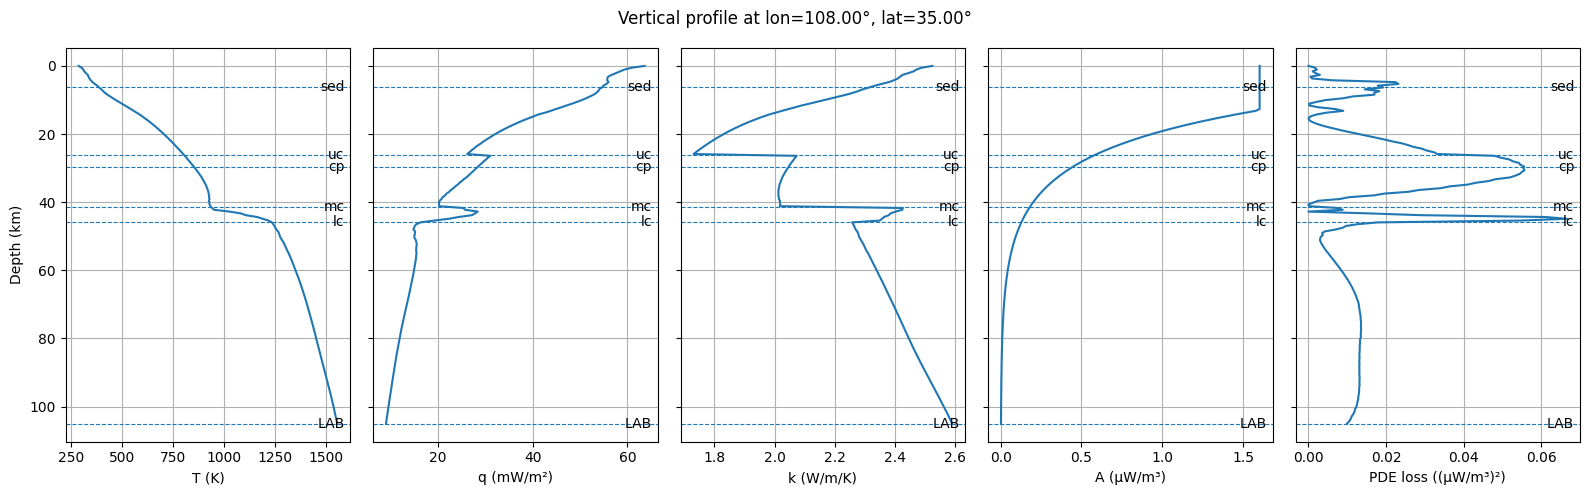

In [56]:
plot_vertical_profile(108.0, 35.0)

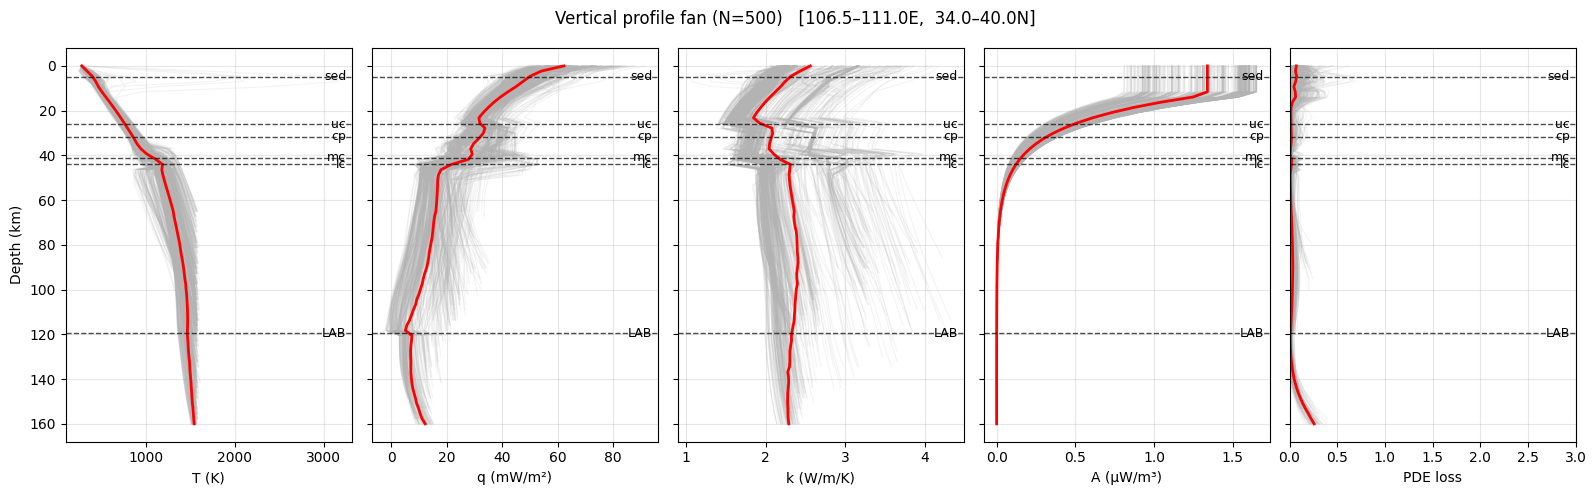

In [57]:
res = plot_vertical_profile_fan(
    lon_min=106.5, lon_max=111.0,
    lat_min=34.0, lat_max=40.0,
    n_locs=500,
    depth_max_km=160.0,
    nz=70
)

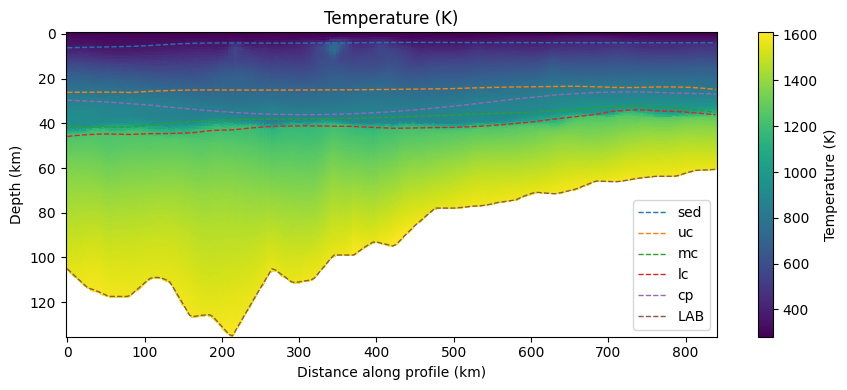

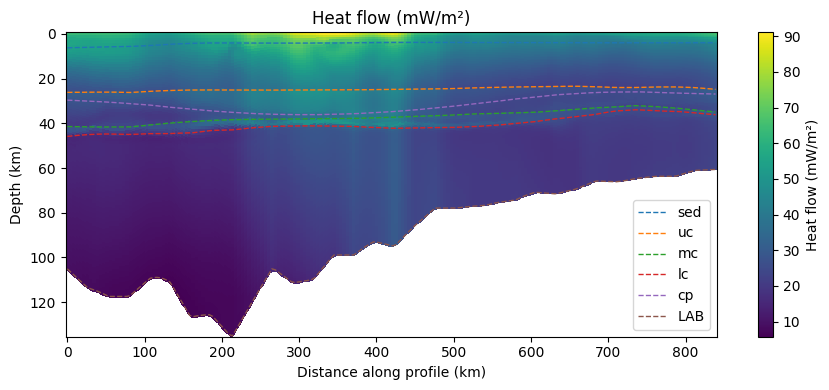

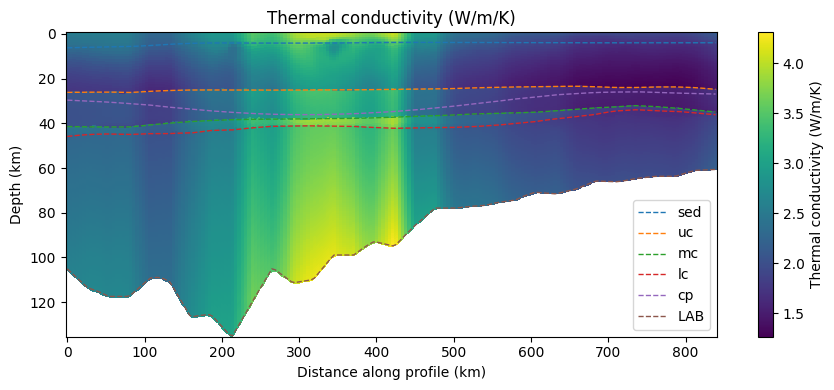

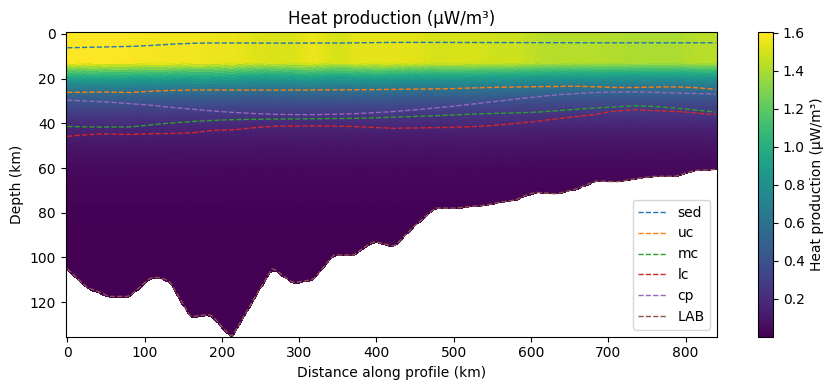

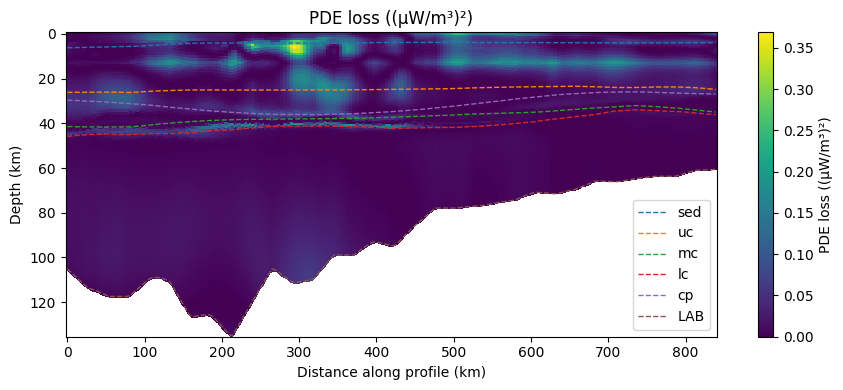

In [58]:
# 比如：从 (108E, 35N) 到 (116E, 39N) 的温度、热流、热导率、生热率剖面
plot_section(108.0, 35.0, 116.0, 39.0, nx=200, nz=100, field="T")
plot_section(108.0, 35.0, 116.0, 39.0, nx=200, nz=100, field="q")
plot_section(108.0, 35.0, 116.0, 39.0, nx=200, nz=100, field="k")
plot_section(108.0, 35.0, 116.0, 39.0, nx=200, nz=100, field="A")
plot_section(108.0, 35.0, 116.0, 39.0, nx=200, nz=100, field="pde")


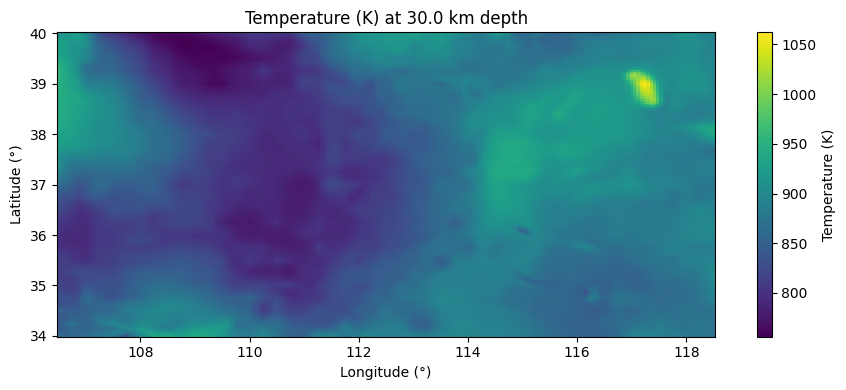

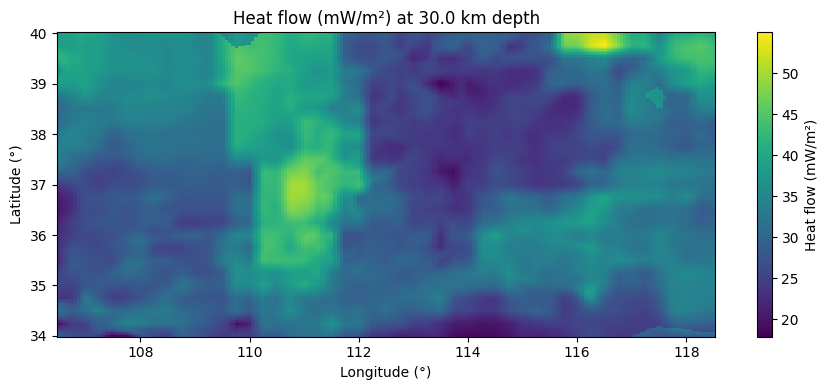

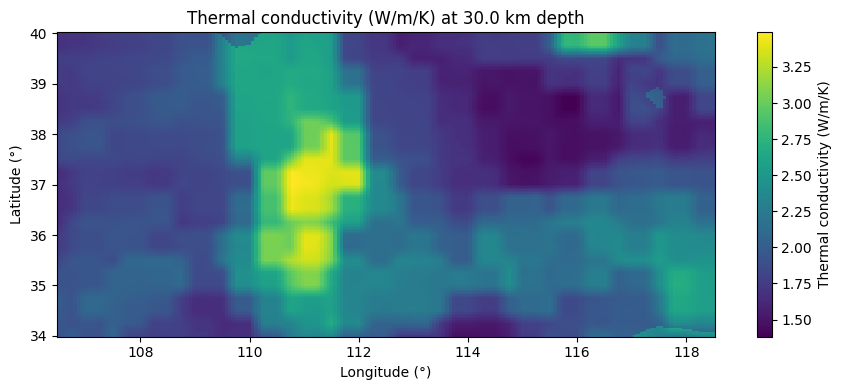

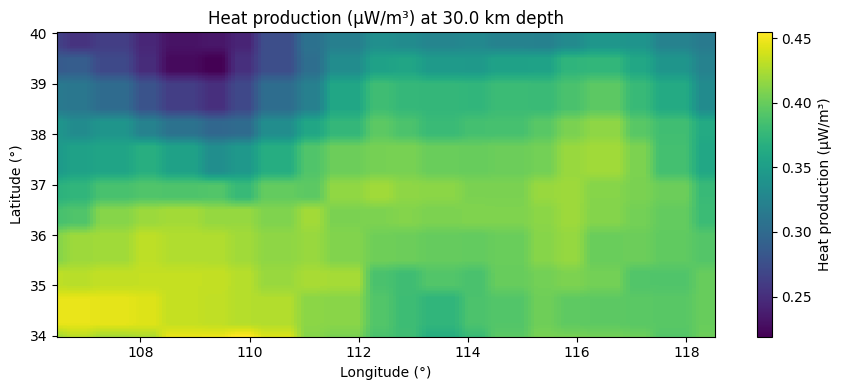

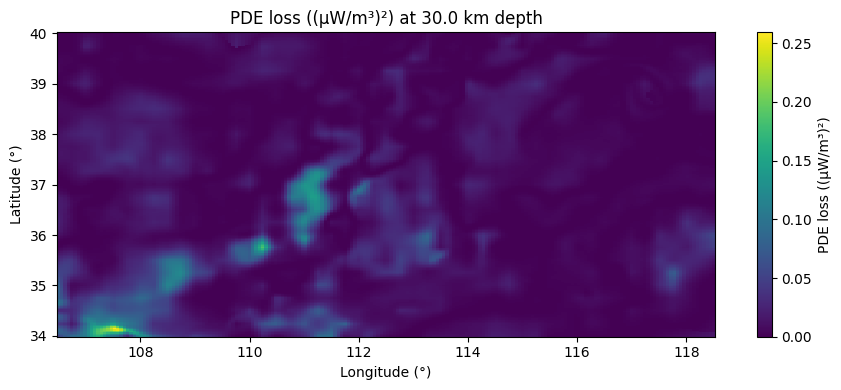

In [59]:
# 20 km 深度处的温度切片
plot_depth_slice(30.0, nx=200, ny=200, field="T")
plot_depth_slice(30.0, nx=200, ny=200, field="q")
plot_depth_slice(30.0, nx=200, ny=200, field="k")
plot_depth_slice(30.0, nx=200, ny=200, field="A")
plot_depth_slice(30.0, nx=200, ny=200, field="pde")


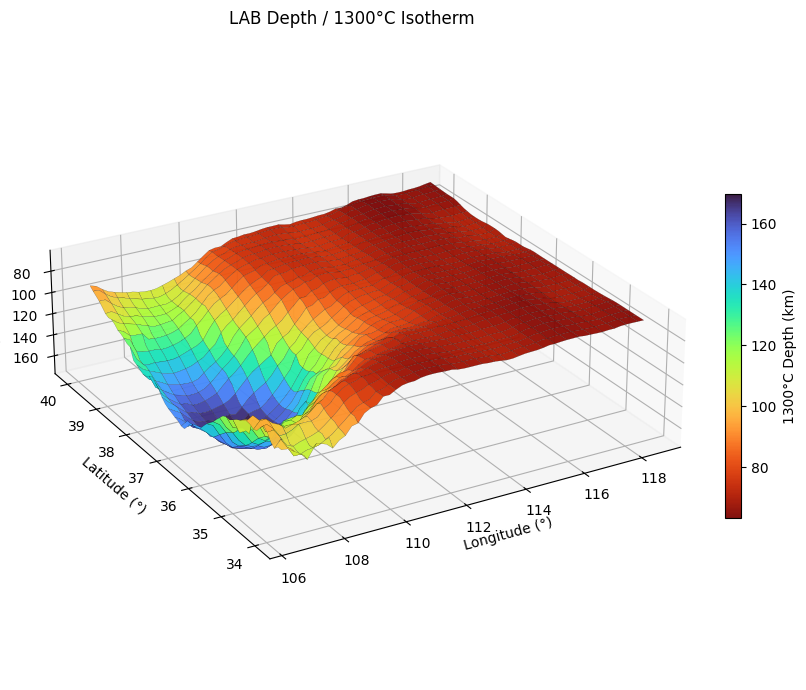

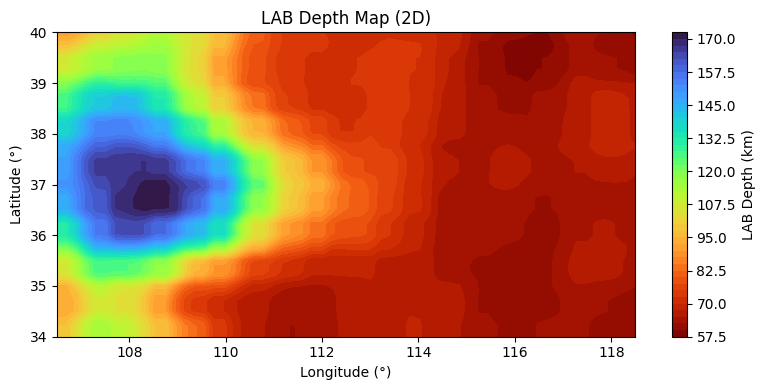

In [63]:
result = plot_T1300_isotherm_3d_ll(
    lon_min=106.5, lon_max=118.5,
    lat_min=34.0,  lat_max=40.0,
    nx=60, ny=60, nz=80,
    T_iso_C=1300.0
)


/tmp/ipykernel_692/3979779543.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("turbo")


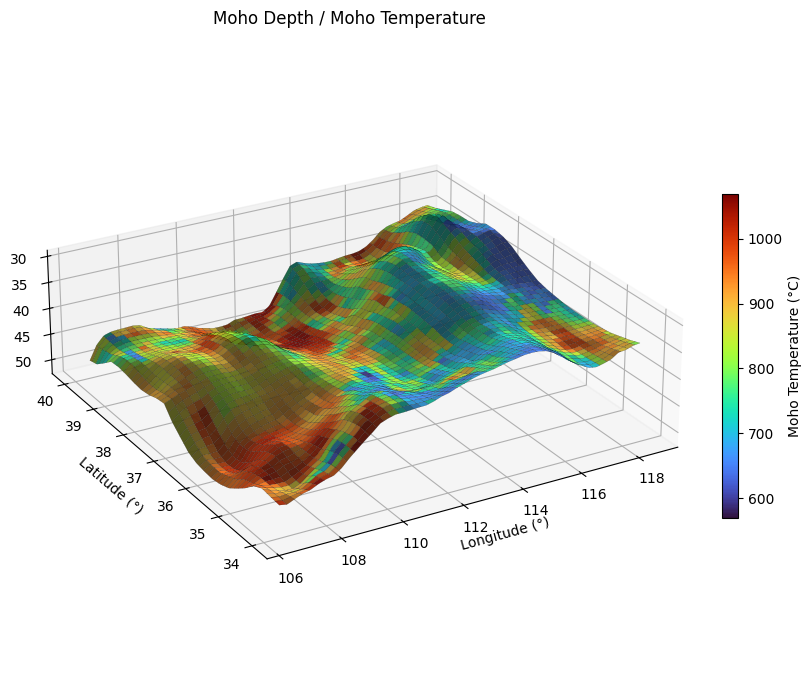

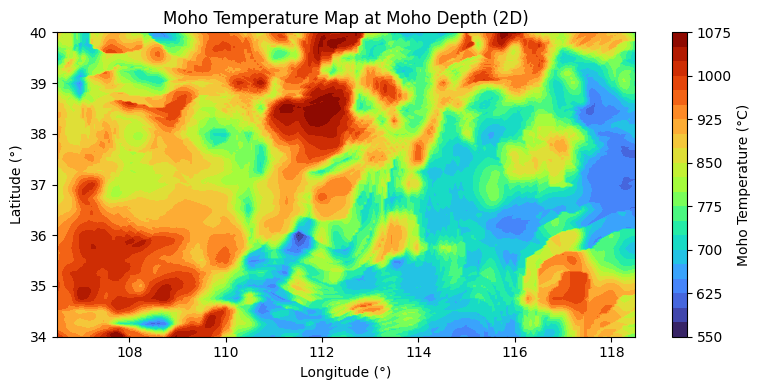

In [71]:
T_moho_C, depth_moho = plot_moho_temperature_3d_ll()

In [ ]:
# 清空缓存
torch.cuda.empty_cache()